# SmartStay AI — Entrenamiento, validación y selección de modelos

Este notebook documenta los cinco algoritmos de regresión, el seguimiento con MLflow, el MLP base y sus tres experimentos, la optimización y los análisis complementarios.

**Modelo principal seleccionado:** Random Forest general optimizado (`models/mejor_modelo.joblib`), utilizado en Streamlit para predecir precios de alojamientos sin restringirlos previamente por su precio real. **Experimento complementario:** Random Forest especializado en registros con precio real ≤500 € (`models/modelo_especializado_500.joblib`).

**Nota metodológica:** las comparaciones de validación fundamentan la selección; las evaluaciones de test ya guardadas se presentan como resultados finales, no como base para reajustar modelos. Se conserva el orden de las celdas Python y sus salidas guardadas; los cambios de esta versión son exclusivamente documentales.

## Índice
1. Carga de datos y preprocesamiento
2. Modelos supervisados y comparativa MLflow
3. Optimización de hiperparámetros
4. Red neuronal MLP y experimentos
5. Estudio de precios extremos y especialización experimental
6. SHAP del modelo especializado sobre validación
7. Experimentos complementarios
8. Modelo general seleccionado y SHAP exploratorio
9. Experimento especializado y análisis del conjunto de test
10. Conclusiones y limitaciones


## 1. Carga de datos y preprocesamiento

In [1]:
import pandas as pd
from pathlib import Path

# Cargar datos preparados
ruta = Path("../data/processed")

X_train = pd.read_csv(ruta / "X_train.csv")
X_test = pd.read_csv(ruta / "X_test.csv")

y_train = pd.read_csv(ruta / "y_train.csv")["price"]
y_test = pd.read_csv(ruta / "y_test.csv")["price"]

# Definir variables predictoras
variables_numericas = [
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "number_of_reviews_ltm"
]

variables_categoricas = [
    "zona",
    "room_type",
    "estancia_larga"
]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("\nVariables predictoras:")
print(X_train.columns.tolist())

print("\nNulos en estancia_larga:")
print(X_train["estancia_larga"].isna().sum())

X_train: (71691, 11)
X_test: (17923, 11)
y_train: (71691,)
y_test: (17923,)

Variables predictoras:
['latitude', 'longitude', 'minimum_nights', 'number_of_reviews', 'reviews_per_month', 'calculated_host_listings_count', 'availability_365', 'number_of_reviews_ltm', 'zona', 'room_type', 'estancia_larga']

Nulos en estancia_larga:
7791


### Pipeline de preprocesamiento

Se construye un Pipeline de preprocesamiento mediante scikit-learn para transformar las variables predictoras antes del entrenamiento.

**Variables numéricas (8):**

Se aplica `SimpleImputer(strategy="median")` para tratar valores ausentes y posteriormente `StandardScaler()` para estandarizar las variables.

**Variables categóricas (2):**

Se aplica `OneHotEncoder(handle_unknown="ignore")` para convertir las categorías en variables numéricas.

Ambas transformaciones se combinan mediante `ColumnTransformer`.

El preprocesamiento se ajustará exclusivamente con los datos de entrenamiento para evitar fugas de información hacia el conjunto de prueba.

In [2]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Variables numéricas
pipeline_numerico = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Variables categóricas
pipeline_categorico = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Preprocesamiento completo
preprocessor = ColumnTransformer([
    ("num", pipeline_numerico, variables_numericas),
    ("cat", pipeline_categorico, variables_categoricas)
])

print("Pipeline de preprocesamiento definido correctamente")
print(preprocessor)

Pipeline de preprocesamiento definido correctamente
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['latitude', 'longitude', 'minimum_nights',
                                  'number_of_reviews', 'reviews_per_month',
                                  'calculated_host_listings_count',
                                  'availability_365',
                                  'number_of_reviews_ltm']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore'))]),

### Comprobar MLflow

In [3]:
import mlflow

print("Versión de MLflow:", mlflow.__version__)

mlflow.set_tracking_uri("sqlite:///../resultados/mlflow.db")
mlflow.set_experiment("SmartStay_AI")

Versión de MLflow: 3.17.1


2026/11/05 16:36:38 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/05 16:36:38 INFO mlflow.store.db.utils: Updating database tables
2026/11/05 16:36:40 INFO mlflow.tracking.fluent: Experiment with name 'SmartStay_AI' does not exist. Creating a new experiment.


<Experiment: artifact_location='file:c:/Users/Jon.Gorricho/Desktop/SmartStay_AI/notebooks/mlruns/1', creation_time=1793893000663, effective_trace_archival_retention=None, experiment_id='1', last_update_time=1793893000663, lifecycle_stage='active', name='SmartStay_AI', tags={}, trace_location=None, workspace='default'>

## 2. Modelos supervisados y comparativa MLflow

## Entrenamiento de modelos de Machine Learning

### Modelo 1: Regresión lineal

Se utiliza la regresión lineal como modelo de referencia para la predicción del precio de alojamientos turísticos.

El modelo se integra en un Pipeline que incluye el preprocesamiento de variables numéricas y categóricas.

El entrenamiento se realiza exclusivamente con `X_train` e `y_train`.

Se evaluará su rendimiento mediante validación cruzada y, posteriormente, sobre el conjunto de prueba reservado, utilizando MAE, RMSE y R².

Se conservarán los resultados para compararlos con modelos más complejos.

In [4]:
import mlflow
import time

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import cross_validate
from sklearn.pipeline import Pipeline

# Métricas para validación cruzada
metricas = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

# Modelo con preprocesamiento incluido
modelo_lr = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Registrar experimento
with mlflow.start_run(run_name="Regresion_Lineal"):

    inicio = time.perf_counter()

    # Validación cruzada de 5 particiones
    cv_lr = cross_validate(
        modelo_lr,
        X_train,
        y_train,
        cv=5,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=True
    )

    tiempo = time.perf_counter() - inicio

    # Métricas medias
    mae_train = -cv_lr["train_MAE"].mean()
    mae_val = -cv_lr["test_MAE"].mean()

    rmse_train = -cv_lr["train_RMSE"].mean()
    rmse_val = -cv_lr["test_RMSE"].mean()

    r2_train = cv_lr["train_R2"].mean()
    r2_val = cv_lr["test_R2"].mean()

    # Guardar parámetros
    mlflow.log_param("modelo", "LinearRegression")
    mlflow.log_param("cv_folds", 5)
    mlflow.log_param("variables", X_train.shape[1])

    # Guardar métricas
    mlflow.log_metrics({
        "MAE_train": mae_train,
        "MAE_validacion": mae_val,
        "RMSE_train": rmse_train,
        "RMSE_validacion": rmse_val,
        "R2_train": r2_train,
        "R2_validacion": r2_val,
        "tiempo_segundos": tiempo
    })

    print("REGRESIÓN LINEAL - VALIDACIÓN CRUZADA")
    print("------------------------------------")
    print(f"MAE entrenamiento: {mae_train:.2f} €")
    print(f"MAE validación:    {mae_val:.2f} €")
    print(f"RMSE validación:   {rmse_val:.2f} €")
    print(f"R² validación:     {r2_val:.4f}")
    print(f"Tiempo CV:        {tiempo:.2f} segundos")

2026/11/05 16:37:13 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably not on your PATH), so Git SHA is not available. Error: Failed to initialize: Bad git executable.
The git executable must be specified in one of the following ways:
    - be included in your $PATH
    - be set via $GIT_PYTHON_GIT_EXECUTABLE
    - explicitly set via git.refresh(<full-path-to-git-executable>)

All git commands will error until this is rectified.

This initial message can be silenced or aggravated in the future by setting the
$GIT_PYTHON_REFRESH environment variable. Use one of the following values:
    - quiet|q|silence|s|silent|none|n|0: for no message or exception
    - warn|w|warning|log|l|1: for a warning message (logging level CRITICAL, displayed by default)
    - error|e|exception|raise|r|2: for a raised exception

Example:
    export GIT_PYTHON_REFRESH=quiet

2026/11/05 16:37:13 WARNING mlflow.utils.git_utils: Failed to import Git (the Git executable is probably

REGRESIÓN LINEAL - VALIDACIÓN CRUZADA
------------------------------------
MAE entrenamiento: 165.67 €
MAE validación:    165.70 €
RMSE validación:   665.30 €
R² validación:     0.0715
Tiempo CV:        4.20 segundos


### DummyRegressor con MLflow

In [5]:
import time
import mlflow

from sklearn.dummy import DummyRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

modelo_dummy = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", DummyRegressor(strategy="mean"))
])

with mlflow.start_run(run_name="DummyRegressor"):

    inicio = time.perf_counter()

    cv_dummy = cross_validate(
        modelo_dummy,
        X_train,
        y_train,
        cv=5,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=True
    )

    tiempo = time.perf_counter() - inicio

    mae_train = -cv_dummy["train_MAE"].mean()
    mae_val = -cv_dummy["test_MAE"].mean()

    rmse_train = -cv_dummy["train_RMSE"].mean()
    rmse_val = -cv_dummy["test_RMSE"].mean()

    r2_train = cv_dummy["train_R2"].mean()
    r2_val = cv_dummy["test_R2"].mean()

    mlflow.log_params({
        "modelo": "DummyRegressor",
        "strategy": "mean",
        "cv_folds": 5
    })

    mlflow.log_metrics({
        "MAE_train": mae_train,
        "MAE_validacion": mae_val,
        "RMSE_train": rmse_train,
        "RMSE_validacion": rmse_val,
        "R2_train": r2_train,
        "R2_validacion": r2_val,
        "tiempo_segundos": tiempo
    })

    print("DUMMY REGRESSOR - VALIDACIÓN CRUZADA")
    print("-----------------------------------")
    print(f"MAE entrenamiento: {mae_train:.2f} €")
    print(f"MAE validación:    {mae_val:.2f} €")
    print(f"RMSE validación:   {rmse_val:.2f} €")
    print(f"R² validación:     {r2_val:.4f}")
    print(f"Tiempo CV:        {tiempo:.2f} segundos")

DUMMY REGRESSOR - VALIDACIÓN CRUZADA
-----------------------------------
MAE entrenamiento: 183.21 €
MAE validación:    183.21 €
RMSE validación:   685.56 €
R² validación:     -0.0001
Tiempo CV:        2.89 segundos


### KNeighborsRegressor

In [6]:
import time
import mlflow

from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

modelo_knn = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", KNeighborsRegressor(
        n_neighbors=5,
        weights="distance"
    ))
])

with mlflow.start_run(run_name="KNN_5_vecinos"):

    inicio = time.perf_counter()

    cv_knn = cross_validate(
        modelo_knn,
        X_train,
        y_train,
        cv=5,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=True
    )

    tiempo = time.perf_counter() - inicio

    mae_train = -cv_knn["train_MAE"].mean()
    mae_val = -cv_knn["test_MAE"].mean()

    rmse_train = -cv_knn["train_RMSE"].mean()
    rmse_val = -cv_knn["test_RMSE"].mean()

    r2_train = cv_knn["train_R2"].mean()
    r2_val = cv_knn["test_R2"].mean()

    mlflow.log_params({
        "modelo": "KNeighborsRegressor",
        "n_neighbors": 5,
        "weights": "distance",
        "cv_folds": 5
    })

    mlflow.log_metrics({
        "MAE_train": mae_train,
        "MAE_validacion": mae_val,
        "RMSE_train": rmse_train,
        "RMSE_validacion": rmse_val,
        "R2_train": r2_train,
        "R2_validacion": r2_val,
        "tiempo_segundos": tiempo
    })

    print("KNN - VALIDACIÓN CRUZADA")
    print("-----------------------")
    print(f"MAE entrenamiento: {mae_train:.2f} €")
    print(f"MAE validación:    {mae_val:.2f} €")
    print(f"RMSE validación:   {rmse_val:.2f} €")
    print(f"R² validación:     {r2_val:.4f}")
    print(f"Tiempo CV:        {tiempo:.2f} segundos")

KNN - VALIDACIÓN CRUZADA
-----------------------
MAE entrenamiento: 1.56 €
MAE validación:    136.69 €
RMSE validación:   650.50 €
R² validación:     0.1219
Tiempo CV:        30.92 segundos


### Random Forest

In [7]:
import time
import mlflow

from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

modelo_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        max_depth=15,
        min_samples_leaf=5,
        random_state=42,
        n_jobs=1
    ))
])

with mlflow.start_run(run_name="RandomForest_100_arboles"):

    inicio = time.perf_counter()

    cv_rf = cross_validate(
        modelo_rf,
        X_train,
        y_train,
        cv=5,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=True
    )

    tiempo = time.perf_counter() - inicio

    mae_train = -cv_rf["train_MAE"].mean()
    mae_val = -cv_rf["test_MAE"].mean()

    rmse_train = -cv_rf["train_RMSE"].mean()
    rmse_val = -cv_rf["test_RMSE"].mean()

    r2_train = cv_rf["train_R2"].mean()
    r2_val = cv_rf["test_R2"].mean()

    mlflow.log_params({
        "modelo": "RandomForestRegressor",
        "n_estimators": 100,
        "max_depth": 15,
        "min_samples_leaf": 5,
        "random_state": 42,
        "cv_folds": 5
    })

    mlflow.log_metrics({
        "MAE_train": mae_train,
        "MAE_validacion": mae_val,
        "RMSE_train": rmse_train,
        "RMSE_validacion": rmse_val,
        "R2_train": r2_train,
        "R2_validacion": r2_val,
        "tiempo_segundos": tiempo
    })

    print("RANDOM FOREST - VALIDACIÓN CRUZADA")
    print("---------------------------------")
    print(f"MAE entrenamiento: {mae_train:.2f} €")
    print(f"MAE validación:    {mae_val:.2f} €")
    print(f"RMSE validación:   {rmse_val:.2f} €")
    print(f"R² validación:     {r2_val:.4f}")
    print(f"Tiempo CV:        {tiempo:.2f} segundos")

RANDOM FOREST - VALIDACIÓN CRUZADA
---------------------------------
MAE entrenamiento: 112.52 €
MAE validación:    129.74 €
RMSE validación:   616.81 €
R² validación:     0.2316
Tiempo CV:        41.37 segundos


### XGBoost

In [8]:
import time
import mlflow

from xgboost import XGBRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

modelo_xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=1
    ))
])

with mlflow.start_run(run_name="XGBoost_200_arboles"):

    inicio = time.perf_counter()

    cv_xgb = cross_validate(
        modelo_xgb,
        X_train,
        y_train,
        cv=5,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=True
    )

    tiempo = time.perf_counter() - inicio

    mae_train = -cv_xgb["train_MAE"].mean()
    mae_val = -cv_xgb["test_MAE"].mean()

    rmse_train = -cv_xgb["train_RMSE"].mean()
    rmse_val = -cv_xgb["test_RMSE"].mean()

    r2_train = cv_xgb["train_R2"].mean()
    r2_val = cv_xgb["test_R2"].mean()

    mlflow.log_params({
        "modelo": "XGBRegressor",
        "n_estimators": 200,
        "max_depth": 6,
        "learning_rate": 0.05,
        "subsample": 0.8,
        "colsample_bytree": 0.8,
        "cv_folds": 5
    })

    mlflow.log_metrics({
        "MAE_train": mae_train,
        "MAE_validacion": mae_val,
        "RMSE_train": rmse_train,
        "RMSE_validacion": rmse_val,
        "R2_train": r2_train,
        "R2_validacion": r2_val,
        "tiempo_segundos": tiempo
    })

    print("XGBOOST - VALIDACIÓN CRUZADA")
    print("---------------------------")
    print(f"MAE entrenamiento: {mae_train:.2f} €")
    print(f"MAE validación:    {mae_val:.2f} €")
    print(f"RMSE validación:   {rmse_val:.2f} €")
    print(f"R² validación:     {r2_val:.4f}")
    print(f"Tiempo CV:        {tiempo:.2f} segundos")

XGBOOST - VALIDACIÓN CRUZADA
---------------------------
MAE entrenamiento: 118.61 €
MAE validación:    132.82 €
RMSE validación:   630.20 €
R² validación:     0.1944
Tiempo CV:        3.57 segundos


### SVR (Support Vector Regression)

In [9]:
import time
import mlflow

from sklearn.svm import LinearSVR
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

modelo_svr = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearSVR(
        C=1.0,
        epsilon=0.0,
        max_iter=5000,
        random_state=42
    ))
])

with mlflow.start_run(run_name="LinearSVR"):

    inicio = time.perf_counter()

    cv_svr = cross_validate(
        modelo_svr,
        X_train,
        y_train,
        cv=5,
        scoring=metricas,
        n_jobs=-1,
        return_train_score=True
    )

    tiempo = time.perf_counter() - inicio

    mae_train = -cv_svr["train_MAE"].mean()
    mae_val = -cv_svr["test_MAE"].mean()

    rmse_train = -cv_svr["train_RMSE"].mean()
    rmse_val = -cv_svr["test_RMSE"].mean()

    r2_train = cv_svr["train_R2"].mean()
    r2_val = cv_svr["test_R2"].mean()

    mlflow.log_params({
        "modelo": "LinearSVR",
        "C": 1.0,
        "epsilon": 0.0,
        "max_iter": 5000,
        "cv_folds": 5
    })

    mlflow.log_metrics({
        "MAE_train": mae_train,
        "MAE_validacion": mae_val,
        "RMSE_train": rmse_train,
        "RMSE_validacion": rmse_val,
        "R2_train": r2_train,
        "R2_validacion": r2_val,
        "tiempo_segundos": tiempo
    })

    print("LINEAR SVR - VALIDACIÓN CRUZADA")
    print("------------------------------")
    print(f"MAE entrenamiento: {mae_train:.2f} €")
    print(f"MAE validación:    {mae_val:.2f} €")
    print(f"RMSE validación:   {rmse_val:.2f} €")
    print(f"R² validación:     {r2_val:.4f}")
    print(f"Tiempo CV:        {tiempo:.2f} segundos")

LINEAR SVR - VALIDACIÓN CRUZADA
------------------------------
MAE entrenamiento: 137.11 €
MAE validación:    137.14 €
RMSE validación:   678.30 €
R² validación:     0.0265
Tiempo CV:        1.06 segundos


### Recuperar los experimentos desde MLflow

In [10]:
import mlflow
import pandas as pd

# Recuperar el experimento
experimento = mlflow.get_experiment_by_name("SmartStay_AI")

# Consultar todas las ejecuciones registradas
runs = mlflow.search_runs(
    experiment_ids=[experimento.experiment_id]
)

# Seleccionar métricas relevantes
columnas = [
    "tags.mlflow.runName",
    "metrics.MAE_train",
    "metrics.MAE_validacion",
    "metrics.RMSE_train",
    "metrics.RMSE_validacion",
    "metrics.R2_train",
    "metrics.R2_validacion",
    "metrics.tiempo_segundos"
]

tabla_modelos = runs[columnas].copy()

# Renombrar columnas
tabla_modelos.columns = [
    "Modelo",
    "MAE Train",
    "MAE Validación",
    "RMSE Train",
    "RMSE Validación",
    "R² Train",
    "R² Validación",
    "Tiempo (s)"
]

# Ordenar de mejor a peor según MAE
tabla_modelos = tabla_modelos.sort_values(
    by="MAE Validación"
).reset_index(drop=True)

display(tabla_modelos.round(3))

,Modelo,MAE Train,MAE Validación,RMSE Train,RMSE Validación,R² Train,R² Validación,Tiempo (s)
0,RandomForest_100_arboles,112.520,129.736,578.133,616.807,0.370,0.232,41.371
1,XGBoost_200_arboles,118.612,132.819,367.210,630.204,0.740,0.194,3.571
2,KNN_5_vecinos,1.558,136.693,14.179,650.501,1.000,0.122,30.919
3,LinearSVR,137.109,137.142,720.668,678.300,0.017,0.026,1.056
4,Regresion_Lineal,165.666,165.704,709.310,665.302,0.048,0.072,4.202
5,DummyRegressor,183.207,183.213,726.617,685.556,0.000,-0.000,2.887


## Comparativa de modelos de Machine Learning — SmartStay AI

### 1. Metodología de evaluación

Se han entrenado cinco familias de algoritmos de regresión supervisada y un modelo adicional de referencia (*DummyRegressor*).

Los experimentos se han realizado utilizando:

- **Dataset de entrenamiento:** 71.691 alojamientos.
- **Variables predictoras:** 11, incluida la nueva variable `estancia_larga`.
- **Validación cruzada:** 5 particiones (*5-Fold Cross Validation*).
- **Preprocesamiento:** imputación de valores nulos, escalado de variables numéricas y codificación One-Hot de variables categóricas.
- **Métricas:** MAE, RMSE y R².
- **Seguimiento:** MLflow, registrando métricas de entrenamiento, validación y tiempo de ejecución.

El conjunto de prueba, formado por 17.923 alojamientos, permanece reservado para la evaluación final.

### 2. Resultados registrados en MLflow

Los resultados de la siguiente tabla se han recuperado directamente de MLflow mediante `mlflow.search_runs()`.

| Modelo | MAE Train (€) | MAE Validación (€) | RMSE Train (€) | RMSE Validación (€) | R² Train | R² Validación | Tiempo CV (s) |
|---|---:|---:|---:|---:|---:|---:|---:|
| **Random Forest** | **112,52** | **129,74** | 578,13 | **616,81** | 0,370 | **0,232** | 41,37 |
| XGBoost | 118,61 | 132,82 | 367,21 | 630,20 | 0,740 | 0,194 | 3,57 |
| KNN (5 vecinos) | 1,56 | 136,69 | 14,18 | 650,50 | 1,000 | 0,122 | 30,92 |
| LinearSVR | 137,11 | 137,14 | 720,67 | 678,30 | 0,017 | 0,026 | **1,06** |
| Regresión lineal | 165,67 | 165,70 | 709,31 | 665,30 | 0,048 | 0,072 | 4,20 |
| DummyRegressor | 183,21 | 183,21 | 726,62 | 685,56 | 0,000 | -0,000 | 2,89 |

*Los modelos están ordenados de menor a mayor MAE de validación. Un MAE y RMSE menores indican mejores predicciones; un R² mayor indica mayor capacidad explicativa.*

### 3. Interpretación de los resultados

**DummyRegressor — Modelo de referencia**

Predice el precio medio de los alojamientos sin utilizar relaciones entre las variables predictoras. Su MAE de 183,21 € permite establecer una referencia mínima para evaluar los demás algoritmos.

**Regresión lineal**

Reduce el MAE a 165,70 €, pero presenta un R² de 0,072. Esto indica que las relaciones lineales utilizadas por el modelo no explican suficientemente la variabilidad de los precios.

**KNN — KNeighborsRegressor**

Obtiene un MAE de validación de 136,69 €, mejorando considerablemente la regresión lineal.

Sin embargo, presenta un MAE de entrenamiento de solo 1,56 € y un R² de entrenamiento próximo a 1. La diferencia respecto a validación evidencia un comportamiento de sobreajuste, favorecido por la configuración `weights="distance"`.

**Random Forest**

Consigue los mejores resultados de validación:

- MAE: **129,74 €**.
- RMSE: **616,81 €**.
- R²: **0,232**.

Reduce el MAE aproximadamente un **29,2 % respecto a DummyRegressor** y un **5,1 % respecto a KNN**.

La diferencia entre MAE de entrenamiento (112,52 €) y validación (129,74 €) es moderada en comparación con KNN.

**XGBoost**

Obtiene un MAE de 132,82 €, próximo al de Random Forest.

Su principal ventaja es la velocidad: completa la validación cruzada en 3,57 segundos, frente a los 41,37 segundos de Random Forest en las ejecuciones realizadas.

No obstante, la diferencia entre R² de entrenamiento (0,740) y validación (0,194) sugiere un sobreajuste relevante que conviene investigar mediante la optimización de hiperparámetros.

**LinearSVR**

Consigue un MAE de 137,14 € y presenta el menor tiempo de ejecución (1,06 segundos).

La diferencia entre entrenamiento y validación es mínima, aunque su R² de 0,026 indica que explica muy poca variabilidad del precio. Su RMSE también es elevado.

### 4. Influencia de los precios extremos

Durante el análisis exploratorio se identificaron alojamientos con precios excepcionalmente elevados, llegando hasta 110.700 € por noche.

Estos valores pueden influir considerablemente en el RMSE y el R², especialmente cuando los modelos cometen errores importantes al predecir alojamientos de precio extremo.

Por este motivo, aunque Random Forest presenta el mejor resultado actual, todavía es necesario estudiar estrategias para mejorar la generalización y analizar el impacto de los valores atípicos.

### 5. Conclusión provisional

**Random Forest es el mejor modelo de los evaluados hasta el momento**, porque obtiene simultáneamente el menor MAE, el menor RMSE y el mayor R² de validación.

Sin embargo, XGBoost constituye una alternativa interesante por su velocidad de entrenamiento y sus resultados relativamente próximos.

Los experimentos también muestran que una buena precisión sobre los datos de entrenamiento no garantiza un buen comportamiento sobre datos no vistos, como ocurre especialmente con KNN y XGBoost.

**Próximos pasos:**

1. Optimizar los hiperparámetros de Random Forest y XGBoost mediante validación cruzada.
2. Analizar el impacto de los precios extremos.
3. Comparar los modelos optimizados y los experimentos con MLP.
4. Aplicar SHAP para interpretar las predicciones del modelo seleccionado.
5. Seleccionar el modelo definitivo considerando precisión, generalización, complejidad y utilidad para el negocio.

La evaluación final sobre el conjunto de prueba se realizará una sola vez, después de seleccionar el modelo definitivo, utilizando Streamlit.

**Conclusión:** los resultados actuales permiten identificar Random Forest como principal candidato, pero todavía no justifican considerarlo el modelo definitivo de SmartStay AI.

## 3. Optimización de hiperparámetros

### Preparar RandomizedSearchCV

In [11]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline

# Pipeline completo
pipeline_rf = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        random_state=42,
        n_jobs=1
    ))
])

# Hiperparámetros que vamos a explorar
parametros_rf = {
    "regressor__n_estimators": [100, 150, 200],
    "regressor__max_depth": [10, 15, 20, None],
    "regressor__min_samples_leaf": [2, 5, 10],
    "regressor__max_features": [0.7, 1.0]
}

# Búsqueda aleatoria con validación cruzada
busqueda_rf = RandomizedSearchCV(
    estimator=pipeline_rf,
    param_distributions=parametros_rf,
    n_iter=12,
    scoring="neg_mean_absolute_error",
    cv=5,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Búsqueda de hiperparámetros preparada.")

Búsqueda de hiperparámetros preparada.


In [12]:
import time

inicio = time.time()

# Ejecutar búsqueda de hiperparámetros
busqueda_rf.fit(X_train, y_train)

tiempo_rf = time.time() - inicio

print("Optimización finalizada")
print("---------------------------")
print("Mejores hiperparámetros:")
print(busqueda_rf.best_params_)

print("\nMejor MAE de validación:")
print(round(-busqueda_rf.best_score_, 2), "€")

print("\nTiempo total:")
print(round(tiempo_rf, 2), "segundos")

Fitting 5 folds for each of 12 candidates, totalling 60 fits
Optimización finalizada
---------------------------
Mejores hiperparámetros:
{'regressor__n_estimators': 100, 'regressor__min_samples_leaf': 2, 'regressor__max_features': 0.7, 'regressor__max_depth': None}

Mejor MAE de validación:
124.32 €

Tiempo total:
702.68 segundos


### Registrar el resultado en MLflow

In [14]:
import mlflow
import mlflow.sklearn

with mlflow.start_run(run_name="RandomForest_Optimizado"):

    mlflow.log_params(busqueda_rf.best_params_)

    mlflow.log_metric(
        "MAE_CV",
        -busqueda_rf.best_score_
    )

    mlflow.log_metric(
        "tiempo_optimizacion_seg",
        tiempo_rf
    )

    mlflow.sklearn.log_model(
        sk_model=busqueda_rf.best_estimator_,
        name="random_forest_optimizado",
        skops_trusted_types=[
            "numpy.dtype",
            "sklearn.tree._tree.Tree"
        ]
    )

print("Random Forest optimizado registrado en MLflow.")

Random Forest optimizado registrado en MLflow.


In [15]:
# Comprobar el registro de Random Forest optimizado

runs = mlflow.search_runs(
    experiment_names=["SmartStay_AI"]
)

columnas = [
    "tags.mlflow.runName",
    "metrics.MAE_CV",
    "metrics.tiempo_optimizacion_seg",
    "status"
]

display(
    runs[
        runs["tags.mlflow.runName"] == "RandomForest_Optimizado"
    ][columnas]
)

,tags.mlflow.runName,metrics.MAE_CV,metrics.tiempo_optimizacion_seg,status
0,RandomForest_Optimizado,124.320836,702.681934,FINISHED
1,RandomForest_Optimizado,124.320836,702.681934,FAILED


### Optimizar XGBoost

In [16]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

# Pipeline completo de XGBoost
pipeline_xgb = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", XGBRegressor(
        random_state=42,
        objective="reg:squarederror",
        n_jobs=2,
        tree_method="hist"
    ))
])

# Hiperparámetros
parametros_xgb = {
    "regressor__n_estimators": [100, 200, 300],
    "regressor__max_depth": [3, 5, 7],
    "regressor__learning_rate": [0.03, 0.05, 0.1],
    "regressor__subsample": [0.8, 1.0]
}

# Búsqueda reducida: 5 combinaciones × 3 folds
busqueda_xgb = RandomizedSearchCV(
    estimator=pipeline_xgb,
    param_distributions=parametros_xgb,
    n_iter=5,
    scoring="neg_mean_absolute_error",
    cv=3,
    random_state=42,
    n_jobs=2,
    verbose=2
)

print("Búsqueda de XGBoost preparada.")

Búsqueda de XGBoost preparada.


In [17]:
import time

inicio_xgb = time.time()

# Ejecutar la búsqueda
busqueda_xgb.fit(X_train, y_train)

tiempo_xgb = time.time() - inicio_xgb

print("\nOptimización XGBoost finalizada")
print("--------------------------------")

print("\nMejores hiperparámetros:")
print(busqueda_xgb.best_params_)

print("\nMejor MAE de validación:")
print(round(-busqueda_xgb.best_score_, 2), "€")

print("\nTiempo total:")
print(round(tiempo_xgb, 2), "segundos")

Fitting 3 folds for each of 5 candidates, totalling 15 fits

Optimización XGBoost finalizada
--------------------------------

Mejores hiperparámetros:
{'regressor__subsample': 0.8, 'regressor__n_estimators': 100, 'regressor__max_depth': 7, 'regressor__learning_rate': 0.1}

Mejor MAE de validación:
132.95 €

Tiempo total:
18.56 segundos


### Registrar XGBoost en MLflow

In [19]:
import mlflow
import mlflow.sklearn

with mlflow.start_run(run_name="XGBoost_Optimizado"):

    mlflow.log_params(busqueda_xgb.best_params_)

    mlflow.log_metric(
        "MAE_CV",
        -busqueda_xgb.best_score_
    )

    mlflow.log_metric(
        "tiempo_optimizacion_seg",
        tiempo_xgb
    )

    mlflow.set_tag("CV_folds", "3")
    mlflow.set_tag("n_iter", "5")

    mlflow.sklearn.log_model(
        sk_model=busqueda_xgb.best_estimator_,
        name="xgboost_optimizado",
        skops_trusted_types=[
            "numpy.dtype",
            "xgboost.sklearn.XGBRegressor",
            "xgboost.core.Booster"
        ]
    )

print("XGBoost optimizado registrado en MLflow.")

XGBoost optimizado registrado en MLflow.


## 4. Red neuronal MLP: modelo base y tres experimentos

## MLP base

In [20]:
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline

pipeline_mlp = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", MLPRegressor(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        learning_rate_init=0.001,
        max_iter=100,
        early_stopping=True,
        random_state=42
    ))
])

print("Pipeline MLP base preparado.")

Pipeline MLP base preparado.


In [21]:
import time
import numpy as np

from sklearn.model_selection import cross_validate

inicio_mlp = time.time()

resultados_mlp = cross_validate(
    pipeline_mlp,
    X_train,
    y_train,
    cv=3,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

tiempo_mlp = time.time() - inicio_mlp

print("RESULTADOS MLP BASE")
print("----------------------------")

print("MAE entrenamiento:",
      round(-np.mean(resultados_mlp["train_MAE"]), 2), "€")

print("MAE validación:",
      round(-np.mean(resultados_mlp["test_MAE"]), 2), "€")

print("RMSE validación:",
      round(-np.mean(resultados_mlp["test_RMSE"]), 2), "€")

print("R² validación:",
      round(np.mean(resultados_mlp["test_R2"]), 4))

print("Tiempo:",
      round(tiempo_mlp, 2), "segundos")

c:\Users\Jon.Gorricho\AppData\Local\anaconda3\envs\ia_jag\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(
c:\Users\Jon.Gorricho\AppData\Local\anaconda3\envs\ia_jag\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


RESULTADOS MLP BASE
----------------------------
MAE entrenamiento: 146.2 €
MAE validación: 146.88 €
RMSE validación: 635.33 €
R² validación: 0.1384
Tiempo: 47.81 segundos


c:\Users\Jon.Gorricho\AppData\Local\anaconda3\envs\ia_jag\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (100) reached and the optimization hasn't converged yet.
  warnings.warn(


## Registrar el MLP base en MLflow

In [22]:
import mlflow
import numpy as np

with mlflow.start_run(run_name="MLP_Base"):

    mlflow.log_params({
        "hidden_layer_sizes": "(64, 32)",
        "activation": "relu",
        "solver": "adam",
        "learning_rate_init": 0.001,
        "max_iter": 100,
        "early_stopping": True,
        "cv_folds": 3
    })

    mlflow.log_metric(
        "MAE_train",
        -np.mean(resultados_mlp["train_MAE"])
    )

    mlflow.log_metric(
        "MAE_CV",
        -np.mean(resultados_mlp["test_MAE"])
    )

    mlflow.log_metric(
        "RMSE_train",
        -np.mean(resultados_mlp["train_RMSE"])
    )

    mlflow.log_metric(
        "RMSE_CV",
        -np.mean(resultados_mlp["test_RMSE"])
    )

    mlflow.log_metric(
        "R2_train",
        np.mean(resultados_mlp["train_R2"])
    )

    mlflow.log_metric(
        "R2_CV",
        np.mean(resultados_mlp["test_R2"])
    )

    mlflow.log_metric(
        "tiempo_seg",
        tiempo_mlp
    )

print("MLP base registrado correctamente en MLflow.")

MLP base registrado correctamente en MLflow.


### Experimento 1: aumentar las iteraciones

In [23]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import time

# Experimento 1: aumentar las iteraciones
mlp_exp1 = clone(pipeline_mlp)

mlp_exp1.set_params(
    regressor__max_iter=300
)

inicio = time.time()

resultados_exp1 = cross_validate(
    mlp_exp1,
    X_train,
    y_train,
    cv=3,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

tiempo_exp1 = time.time() - inicio

print("EXPERIMENTO 1 - MLP 300 ITERACIONES")
print("-----------------------------------")

print("MAE entrenamiento:",
      round(-np.mean(resultados_exp1["train_MAE"]), 2), "€")

print("MAE validación:",
      round(-np.mean(resultados_exp1["test_MAE"]), 2), "€")

print("RMSE validación:",
      round(-np.mean(resultados_exp1["test_RMSE"]), 2), "€")

print("R² validación:",
      round(np.mean(resultados_exp1["test_R2"]), 4))

print("Tiempo:",
      round(tiempo_exp1, 2), "segundos")

EXPERIMENTO 1 - MLP 300 ITERACIONES
-----------------------------------
MAE entrenamiento: 142.69 €
MAE validación: 143.68 €
RMSE validación: 632.14 €
R² validación: 0.1491
Tiempo: 109.54 segundos


## Registrar el experimento 1 en MLflow

In [24]:
import mlflow
import numpy as np

with mlflow.start_run(run_name="MLP_Experimento_1"):

    mlflow.log_params({
        "hidden_layer_sizes": "(64, 32)",
        "activation": "relu",
        "solver": "adam",
        "learning_rate_init": 0.001,
        "max_iter": 300,
        "early_stopping": True,
        "cv_folds": 3
    })

    mlflow.log_metric(
        "MAE_train",
        -np.mean(resultados_exp1["train_MAE"])
    )

    mlflow.log_metric(
        "MAE_CV",
        -np.mean(resultados_exp1["test_MAE"])
    )

    mlflow.log_metric(
        "RMSE_train",
        -np.mean(resultados_exp1["train_RMSE"])
    )

    mlflow.log_metric(
        "RMSE_CV",
        -np.mean(resultados_exp1["test_RMSE"])
    )

    mlflow.log_metric(
        "R2_train",
        np.mean(resultados_exp1["train_R2"])
    )

    mlflow.log_metric(
        "R2_CV",
        np.mean(resultados_exp1["test_R2"])
    )

    mlflow.log_metric(
        "tiempo_seg",
        tiempo_exp1
    )

    mlflow.set_tag(
        "hipotesis",
        "Aumentar max_iter de 100 a 300 mejora la convergencia"
    )

print("Experimento 1 registrado correctamente en MLflow.")

Experimento 1 registrado correctamente en MLflow.


### Experimento 2: aumentar las neuronas

Hipótesis: aumentar el número de neuronas podría permitir que el MLP aprenda relaciones más complejas entre las características de los alojamientos y sus precios. Sin embargo, también podría aumentar el sobreajuste y el tiempo de entrenamiento.

In [25]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import time

# Experimento 2: aumentar el número de neuronas
mlp_exp2 = clone(mlp_exp1)

mlp_exp2.set_params(
    regressor__hidden_layer_sizes=(128, 64)
)

inicio = time.time()

resultados_exp2 = cross_validate(
    mlp_exp2,
    X_train,
    y_train,
    cv=3,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

tiempo_exp2 = time.time() - inicio

print("EXPERIMENTO 2 - MLP (128, 64)")
print("-----------------------------------")

print("MAE entrenamiento:",
      round(-np.mean(resultados_exp2["train_MAE"]), 2), "€")

print("MAE validación:",
      round(-np.mean(resultados_exp2["test_MAE"]), 2), "€")

print("RMSE validación:",
      round(-np.mean(resultados_exp2["test_RMSE"]), 2), "€")

print("R² validación:",
      round(np.mean(resultados_exp2["test_R2"]), 4))

print("Tiempo:",
      round(tiempo_exp2, 2), "segundos")

EXPERIMENTO 2 - MLP (128, 64)
-----------------------------------
MAE entrenamiento: 144.64 €
MAE validación: 145.61 €
RMSE validación: 631.55 €
R² validación: 0.1524
Tiempo: 133.99 segundos


## Registrar el experimento 2 en MLflow

In [26]:
import mlflow
import numpy as np

with mlflow.start_run(run_name="MLP_Experimento_2"):

    mlflow.log_params({
        "hidden_layer_sizes": "(128, 64)",
        "activation": "relu",
        "solver": "adam",
        "learning_rate_init": 0.001,
        "max_iter": 300,
        "early_stopping": True,
        "cv_folds": 3
    })

    mlflow.log_metric(
        "MAE_train",
        -np.mean(resultados_exp2["train_MAE"])
    )

    mlflow.log_metric(
        "MAE_CV",
        -np.mean(resultados_exp2["test_MAE"])
    )

    mlflow.log_metric(
        "RMSE_train",
        -np.mean(resultados_exp2["train_RMSE"])
    )

    mlflow.log_metric(
        "RMSE_CV",
        -np.mean(resultados_exp2["test_RMSE"])
    )

    mlflow.log_metric(
        "R2_train",
        np.mean(resultados_exp2["train_R2"])
    )

    mlflow.log_metric(
        "R2_CV",
        np.mean(resultados_exp2["test_R2"])
    )

    mlflow.log_metric(
        "tiempo_seg",
        tiempo_exp2
    )

    mlflow.set_tag(
        "hipotesis",
        "Aumentar las neuronas permite aprender relaciones más complejas"
    )

print("Experimento 2 registrado correctamente en MLflow.")

Experimento 2 registrado correctamente en MLflow.


### Experimento 3: modificar la tasa de aprendizaje

En este experimento vamos a reducir learning_rate_init de 0.001 a 0.0005.

Hipótesis: una tasa de aprendizaje menor puede permitir ajustes más precisos de los pesos de la red neuronal y reducir el MAE, aunque también puede ralentizar la convergencia.

In [27]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import time

# Experimento 3: reducir la tasa de aprendizaje
mlp_exp3 = clone(mlp_exp1)

mlp_exp3.set_params(
    regressor__learning_rate_init=0.0005
)

inicio = time.time()

resultados_exp3 = cross_validate(
    mlp_exp3,
    X_train,
    y_train,
    cv=3,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=1
)

tiempo_exp3 = time.time() - inicio

print("EXPERIMENTO 3 - LEARNING RATE 0.0005")
print("-------------------------------------")

print("MAE entrenamiento:",
      round(-np.mean(resultados_exp3["train_MAE"]), 2), "€")

print("MAE validación:",
      round(-np.mean(resultados_exp3["test_MAE"]), 2), "€")

print("RMSE validación:",
      round(-np.mean(resultados_exp3["test_RMSE"]), 2), "€")

print("R² validación:",
      round(np.mean(resultados_exp3["test_R2"]), 4))

print("Tiempo:",
      round(tiempo_exp3, 2), "segundos")

EXPERIMENTO 3 - LEARNING RATE 0.0005
-------------------------------------
MAE entrenamiento: 145.43 €
MAE validación: 146.31 €
RMSE validación: 633.84 €
R² validación: 0.1432
Tiempo: 142.47 segundos


c:\Users\Jon.Gorricho\AppData\Local\anaconda3\envs\ia_jag\Lib\site-packages\sklearn\neural_network\_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (300) reached and the optimization hasn't converged yet.
  warnings.warn(


## Registrar el experimento 3 en MLflow

In [28]:
import mlflow
import numpy as np

with mlflow.start_run(run_name="MLP_Experimento_3"):

    mlflow.log_params({
        "hidden_layer_sizes": "(64, 32)",
        "activation": "relu",
        "solver": "adam",
        "learning_rate_init": 0.0005,
        "max_iter": 300,
        "early_stopping": True,
        "cv_folds": 3
    })

    mlflow.log_metric(
        "MAE_train",
        -np.mean(resultados_exp3["train_MAE"])
    )

    mlflow.log_metric(
        "MAE_CV",
        -np.mean(resultados_exp3["test_MAE"])
    )

    mlflow.log_metric(
        "RMSE_train",
        -np.mean(resultados_exp3["train_RMSE"])
    )

    mlflow.log_metric(
        "RMSE_CV",
        -np.mean(resultados_exp3["test_RMSE"])
    )

    mlflow.log_metric(
        "R2_train",
        np.mean(resultados_exp3["train_R2"])
    )

    mlflow.log_metric(
        "R2_CV",
        np.mean(resultados_exp3["test_R2"])
    )

    mlflow.log_metric(
        "tiempo_seg",
        tiempo_exp3
    )

    mlflow.set_tag(
        "hipotesis",
        "Reducir learning_rate_init de 0.001 a 0.0005 mejora la precisión"
    )

    mlflow.set_tag(
        "conclusion",
        "No mejora el MAE respecto al experimento 1; se observó aviso de no convergencia"
    )

print("Experimento 3 registrado correctamente en MLflow.")

Experimento 3 registrado correctamente en MLflow.


### Experimentación con redes neuronales MLP

Se ha implementado una red neuronal multicapa (*Multilayer Perceptron*) para predecir el precio por noche de alojamientos turísticos.

La arquitectura inicial consta de dos capas ocultas de 64 y 32 neuronas, función de activación ReLU, optimizador Adam y parada anticipada (*early stopping*).

Se realizaron tres experimentos adicionales:

1. **Experimento 1:** aumentar el máximo de iteraciones de 100 a 300 para permitir un entrenamiento más prolongado.
2. **Experimento 2:** ampliar las capas ocultas a 128 y 64 neuronas para incrementar la capacidad de representación de la red.
3. **Experimento 3:** reducir la tasa de aprendizaje de 0,001 a 0,0005 para estudiar el efecto de actualizaciones más pequeñas de los pesos.

Los cuatro modelos se evaluaron mediante validación cruzada de tres particiones y se registraron en MLflow.

El mejor resultado según MAE corresponde al **experimento 1, con 143,68 €**, frente a los 146,88 € del modelo inicial, lo que supone una mejora aproximada del 2,18 %.

El experimento 2 consiguió el mejor R² (0,1524), pero no mejoró el MAE. La reducción de la tasa de aprendizaje en el experimento 3 tampoco produjo una mejora adicional.

**Conclusión:** aumentar el máximo de iteraciones resultó más beneficioso que ampliar la arquitectura o reducir la tasa de aprendizaje. No obstante, el Random Forest general obtuvo un MAE inferior, por lo que se seleccionó como modelo predictivo principal de SmartStay AI.

## 5. Estudio de precios extremos y especialización experimental


In [29]:
import pandas as pd

# Analizamos únicamente los precios de entrenamiento
precios = y_train.squeeze()

for limite in [500, 750, 1000, 1500, 2000]:
    conservados = (precios <= limite).sum()
    eliminados = (precios > limite).sum()

    print(
        f"Límite {limite:>4} € | "
        f"Conservados: {conservados:>6} | "
        f"Eliminados: {eliminados:>5} | "
        f"Conservado: {conservados / len(precios) * 100:.2f}%"
    )

Límite  500 € | Conservados:  65804 | Eliminados:  5887 | Conservado: 91.79%
Límite  750 € | Conservados:  68598 | Eliminados:  3093 | Conservado: 95.69%
Límite 1000 € | Conservados:  69772 | Eliminados:  1919 | Conservado: 97.32%
Límite 1500 € | Conservados:  70715 | Eliminados:   976 | Conservado: 98.64%
Límite 2000 € | Conservados:  71073 | Eliminados:   618 | Conservado: 99.14%


In [30]:
# Analizar límite de 10.000 €
limite_precio = 10000

y_train_serie = y_train.squeeze()

mascara = y_train_serie <= limite_precio

X_train_10000 = X_train.loc[mascara].copy()
y_train_10000 = y_train_serie.loc[mascara].copy()

print("REGISTROS ORIGINALES:", len(X_train))
print("REGISTROS CONSERVADOS:", len(X_train_10000))
print("REGISTROS ELIMINADOS:", (~mascara).sum())

print(
    "PORCENTAJE CONSERVADO:",
    round(mascara.mean() * 100, 4), "%"
)

print("PRECIO MÁXIMO:", y_train_10000.max(), "€")
print("PRECIO MEDIANO:", y_train_10000.median(), "€")

REGISTROS ORIGINALES: 71691
REGISTROS CONSERVADOS: 71659
REGISTROS ELIMINADOS: 32
PORCENTAJE CONSERVADO: 99.9554 %
PRECIO MÁXIMO: 10000.0 €
PRECIO MEDIANO: 170.0 €


## Entrenar Random Forest con el filtro

In [31]:
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import time

# Reutilizar el mejor Random Forest
rf_10000 = clone(busqueda_rf.best_estimator_)

inicio = time.time()

resultados_rf_10000 = cross_validate(
    rf_10000,
    X_train_10000,
    y_train_10000,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

tiempo_rf_10000 = time.time() - inicio

print("RANDOM FOREST - PRECIOS HASTA 10.000 €")
print("--------------------------------------")

print("MAE entrenamiento:",
      round(-np.mean(resultados_rf_10000["train_MAE"]), 2), "€")

print("MAE validación:",
      round(-np.mean(resultados_rf_10000["test_MAE"]), 2), "€")

print("RMSE validación:",
      round(-np.mean(resultados_rf_10000["test_RMSE"]), 2), "€")

print("R² validación:",
      round(np.mean(resultados_rf_10000["test_R2"]), 4))

print("Tiempo:",
      round(tiempo_rf_10000, 2), "segundos")

RANDOM FOREST - PRECIOS HASTA 10.000 €
--------------------------------------
MAE entrenamiento: 57.62 €
MAE validación: 112.12 €
RMSE validación: 293.99 €
R² validación: 0.431
Tiempo: 46.07 segundos


In [32]:
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np

cv = KFold(n_splits=5, shuffle=False)

mae_original = []
mae_filtrado = []

y = y_train.squeeze()

for train_idx, val_idx in cv.split(X_train):

    X_tr = X_train.iloc[train_idx]
    y_tr = y.iloc[train_idx]

    X_val = X_train.iloc[val_idx]
    y_val = y.iloc[val_idx]

    # Evaluar ambos modelos sobre el mismo segmento
    mascara_val = y_val <= 10000
    X_val_comun = X_val.loc[mascara_val]
    y_val_comun = y_val.loc[mascara_val]

    # Modelo original
    modelo_original = clone(busqueda_rf.best_estimator_)
    modelo_original.fit(X_tr, y_tr)

    pred_original = modelo_original.predict(X_val_comun)

    # Modelo filtrado: el filtro se aplica solo al entrenamiento
    mascara_tr = y_tr <= 10000

    modelo_filtrado = clone(busqueda_rf.best_estimator_)
    modelo_filtrado.fit(
        X_tr.loc[mascara_tr],
        y_tr.loc[mascara_tr]
    )

    pred_filtrado = modelo_filtrado.predict(X_val_comun)

    mae_original.append(
        mean_absolute_error(y_val_comun, pred_original)
    )

    mae_filtrado.append(
        mean_absolute_error(y_val_comun, pred_filtrado)
    )

print("COMPARACIÓN SOBRE LA MISMA VALIDACIÓN")
print("--------------------------------------")
print("MAE original:", round(np.mean(mae_original), 2), "€")
print("MAE filtrado:", round(np.mean(mae_filtrado), 2), "€")
print(
    "Diferencia:",
    round(np.mean(mae_original) - np.mean(mae_filtrado), 2),
    "€"
)

COMPARACIÓN SOBRE LA MISMA VALIDACIÓN
--------------------------------------
MAE original: 117.42 €
MAE filtrado: 112.28 €
Diferencia: 5.13 €


### registrar la comparación en MLflow

In [33]:
import mlflow
import numpy as np

with mlflow.start_run(run_name="RF_Filtrado_10000"):

    mlflow.log_params({
        "modelo": "RandomForestRegressor",
        "precio_maximo_entrenamiento": 10000,
        "registros_excluidos": 32,
        "cv_folds": 5,
        "comparacion_misma_validacion": True
    })

    mlflow.log_metric(
        "MAE_CV_original_mismo_segmento",
        np.mean(mae_original)
    )

    mlflow.log_metric(
        "MAE_CV_filtrado_mismo_segmento",
        np.mean(mae_filtrado)
    )

    mlflow.log_metric(
        "mejora_MAE",
        np.mean(mae_original) - np.mean(mae_filtrado)
    )

    mlflow.log_metric(
        "MAE_CV_filtrado",
        -np.mean(resultados_rf_10000["test_MAE"])
    )

    mlflow.log_metric(
        "RMSE_CV_filtrado",
        -np.mean(resultados_rf_10000["test_RMSE"])
    )

    mlflow.log_metric(
        "R2_CV_filtrado",
        np.mean(resultados_rf_10000["test_R2"])
    )

    mlflow.set_tag(
        "conclusion",
        "Filtrar precios superiores a 10000 mejora el MAE en validacion comparable"
    )

print("Random Forest filtrado registrado en MLflow.")

Random Forest filtrado registrado en MLflow.


### Random Forest con precio logarítmico

In [34]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.base import clone
from sklearn.model_selection import cross_validate
import numpy as np
import time

# Random Forest con transformación logarítmica del precio
rf_log = TransformedTargetRegressor(
    regressor=clone(busqueda_rf.best_estimator_),
    func=np.log1p,
    inverse_func=np.expm1
)

inicio = time.time()

resultados_rf_log = cross_validate(
    rf_log,
    X_train_10000,
    y_train_10000,
    cv=5,
    scoring={
        "MAE": "neg_mean_absolute_error",
        "RMSE": "neg_root_mean_squared_error",
        "R2": "r2"
    },
    return_train_score=True,
    n_jobs=-1
)

tiempo_rf_log = time.time() - inicio

print("RANDOM FOREST CON LOG1P")
print("--------------------------")
print("MAE entrenamiento:",
      round(-np.mean(resultados_rf_log["train_MAE"]), 2), "€")
print("MAE validación:",
      round(-np.mean(resultados_rf_log["test_MAE"]), 2), "€")
print("RMSE validación:",
      round(-np.mean(resultados_rf_log["test_RMSE"]), 2), "€")
print("R² validación:",
      round(np.mean(resultados_rf_log["test_R2"]), 4))
print("Tiempo:", round(tiempo_rf_log, 2), "segundos")

RANDOM FOREST CON LOG1P
--------------------------
MAE entrenamiento: 55.67 €
MAE validación: 100.27 €
RMSE validación: 306.41 €
R² validación: 0.3824
Tiempo: 47.04 segundos


### Siguiente celda: MAE por rangos de precios

In [35]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error
import pandas as pd
import numpy as np

# Predicciones de validación cruzada
predicciones_cv = cross_val_predict(
    rf_log,
    X_train_10000,
    y_train_10000,
    cv=5,
    n_jobs=-1
)

# Crear tabla de análisis
analisis_error = pd.DataFrame({
    "precio_real": np.asarray(y_train_10000),
    "precio_predicho": predicciones_cv
})

analisis_error["error_absoluto"] = abs(
    analisis_error["precio_real"] -
    analisis_error["precio_predicho"]
)

# Agrupar por precio real
analisis_error["rango_precio"] = pd.cut(
    analisis_error["precio_real"],
    bins=[0, 100, 200, 300, 500, 1000, 2000, 10000],
    labels=[
        "0-100 €",
        "100-200 €",
        "200-300 €",
        "300-500 €",
        "500-1000 €",
        "1000-2000 €",
        "2000-10000 €"
    ],
    include_lowest=True
)

resumen_error = (
    analisis_error
    .groupby("rango_precio", observed=True)
    .agg(
        alojamientos=("precio_real", "count"),
        precio_medio=("precio_real", "mean"),
        MAE=("error_absoluto", "mean")
    )
    .round(2)
)

print("ERROR POR RANGOS DE PRECIOS")
print("---------------------------")
print(resumen_error)

ERROR POR RANGOS DE PRECIOS
---------------------------
              alojamientos  precio_medio      MAE
rango_precio                                     
0-100 €              13855         68.59    32.42
100-200 €            29450        147.28    43.07
200-300 €            13825        243.40    58.29
300-500 €             8674        377.96   121.69
500-1000 €            3968        682.60   338.99
1000-2000 €           1301       1345.95   732.78
2000-10000 €           586       3439.41  2231.49


In [36]:
from sklearn.metrics import mean_absolute_error

print("MAE ACUMULADO POR LÍMITE DE PRECIO")
print("----------------------------------")

for limite in [200, 300, 500, 1000, 10000]:

    datos = analisis_error[
        analisis_error["precio_real"] <= limite
    ]

    mae = mean_absolute_error(
        datos["precio_real"],
        datos["precio_predicho"]
    )

    porcentaje = len(datos) / len(analisis_error) * 100

    print(
        f"Hasta {limite:>5} € | "
        f"MAE: {mae:>7.2f} € | "
        f"Alojamientos: {len(datos):>6} | "
        f"Cobertura: {porcentaje:.2f}%"
    )

MAE ACUMULADO POR LÍMITE DE PRECIO
----------------------------------
Hasta   200 € | MAE:   39.66 € | Alojamientos:  43305 | Cobertura: 60.43%
Hasta   300 € | MAE:   44.17 € | Alojamientos:  57130 | Cobertura: 79.72%
Hasta   500 € | MAE:   54.39 € | Alojamientos:  65804 | Cobertura: 91.83%
Hasta  1000 € | MAE:   70.58 € | Alojamientos:  69772 | Cobertura: 97.37%
Hasta 10000 € | MAE:  100.27 € | Alojamientos:  71659 | Cobertura: 100.00%


### Hipótesis experimental: especialización en alojamientos de hasta 500 €

Tras analizar los resultados del Random Forest con transformación logarítmica (`log1p`), se observa que el error de predicción aumenta considerablemente en los alojamientos con precios elevados.

Los resultados de validación cruzada muestran:

| Precio máximo | Cobertura del dataset | MAE |
|---|---:|---:|
| 200 € | 60,43 % | 39,66 € |
| 300 € | 79,72 % | 44,17 € |
| 500 € | 91,83 % | 54,39 € |
| 1.000 € | 97,37 % | 70,58 € |
| 10.000 € | 100 % | 100,27 € |

**Motivación del experimento**

Se decide experimentar con un modelo especializado en alojamientos turísticos de hasta **500 € por noche**, por los siguientes motivos:

1. Este segmento representa aproximadamente el **91,83 % de los alojamientos analizados**, manteniendo una cobertura amplia del mercado.
2. El modelo general obtiene un MAE de **54,39 €** en este segmento, considerablemente inferior al MAE global de 100,27 €.
3. Los alojamientos de precios elevados presentan errores absolutos mucho mayores y dificultan la precisión global.
4. Especializar el entrenamiento podría mejorar las predicciones en el segmento mayoritario del mercado turístico.

**Hipótesis del experimento**

Entrenar un Random Forest con transformación logarítmica utilizando exclusivamente alojamientos de hasta 500 € podría reducir el MAE respecto al modelo general evaluado sobre ese mismo segmento.

**Metodología**

Se entrenará y validará el modelo especializado mediante validación cruzada de cinco particiones, sin utilizar el conjunto de test reservado para la evaluación final.

Se compararán sus resultados con los del modelo general sobre el mismo segmento de alojamientos.

**Limitaciones**

El precio real se utiliza para definir el segmento durante el entrenamiento y la evaluación, pero no estará disponible cuando la aplicación realice una nueva predicción. Por tanto, el modelo especializado deberá presentarse como una herramienta dirigida a un mercado concreto, sin utilizar el precio real desconocido para seleccionar el modelo.

**Criterio de comparación experimental**

Si el modelo especializado reduce significativamente el MAE frente al modelo general, se considerará como candidato para SmartStay AI. En caso contrario, se mantendrá el modelo general con transformación logarítmica.

La decisión definitiva se tomará después de comparar los resultados de validación, teniendo en cuenta tanto la precisión como las limitaciones de

In [37]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error
import numpy as np
import time

# Especialización: alojamientos de hasta 500 €
mascara_500 = y_train_10000 <= 500

X_train_500 = X_train_10000.loc[mascara_500].copy()
y_train_500 = y_train_10000.loc[mascara_500].copy()

modelo_500 = clone(rf_log)

inicio = time.time()

predicciones_500 = cross_val_predict(
    modelo_500,
    X_train_500,
    y_train_500,
    cv=5,
    n_jobs=-1
)

tiempo_500 = time.time() - inicio

mae_500 = mean_absolute_error(
    y_train_500,
    predicciones_500
)

print("MODELO ESPECIALIZADO HASTA 500 €")
print("--------------------------------")
print("Alojamientos:", len(X_train_500))
print("MAE validación:", round(mae_500, 2), "€")
print("Tiempo:", round(tiempo_500, 2), "segundos")

print("\nMODELO GENERAL EN EL MISMO SEGMENTO")
print("MAE:", 54.39, "€")

MODELO ESPECIALIZADO HASTA 500 €
--------------------------------
Alojamientos: 65804
MAE validación: 49.14 €
Tiempo: 42.36 segundos

MODELO GENERAL EN EL MISMO SEGMENTO
MAE: 54.39 €


### Siguiente paso: analizar el sesgo de predicción

In [38]:
import pandas as pd
import numpy as np

analisis_500 = pd.DataFrame({
    "precio_real": np.asarray(y_train_500),
    "precio_predicho": predicciones_500
})

analisis_500["error"] = (
    analisis_500["precio_predicho"]
    - analisis_500["precio_real"]
)

analisis_500["error_absoluto"] = abs(
    analisis_500["error"]
)

analisis_500["rango"] = pd.cut(
    analisis_500["precio_real"],
    bins=[0, 100, 200, 300, 500],
    labels=["0-100 €", "100-200 €", "200-300 €", "300-500 €"],
    include_lowest=True
)

resumen_500 = (
    analisis_500
    .groupby("rango", observed=True)
    .agg(
        alojamientos=("precio_real", "count"),
        precio_medio=("precio_real", "mean"),
        prediccion_media=("precio_predicho", "mean"),
        MAE=("error_absoluto", "mean"),
        sesgo=("error", "mean")
    )
    .round(2)
)

print("ANÁLISIS DEL MODELO ESPECIALIZADO")
print("---------------------------------")
print(resumen_500)

ANÁLISIS DEL MODELO ESPECIALIZADO
---------------------------------
           alojamientos  precio_medio  prediccion_media     MAE   sesgo
rango                                                                  
0-100 €           13855         68.59             92.82   28.25   24.23
100-200 €         29450        147.28            164.21   33.41   16.93
200-300 €         13825        243.40            212.46   49.15  -30.94
300-500 €          8674        377.96            243.07  135.94 -134.89


In [39]:
from sklearn.base import clone
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd

# Random Forest especializado SIN log1p
rf_500_sin_log = clone(busqueda_rf.best_estimator_)

predicciones_500_sin_log = cross_val_predict(
    rf_500_sin_log,
    X_train_500,
    y_train_500,
    cv=5,
    n_jobs=-1
)

# Comparar ambos modelos
comparacion = pd.DataFrame({
    "precio_real": np.asarray(y_train_500),
    "con_log": predicciones_500,
    "sin_log": predicciones_500_sin_log
})

comparacion["rango"] = pd.cut(
    comparacion["precio_real"],
    bins=[0, 100, 200, 300, 500],
    labels=["0-100 €", "100-200 €", "200-300 €", "300-500 €"],
    include_lowest=True
)

print("MAE CON LOG:",
      round(mean_absolute_error(
          comparacion["precio_real"],
          comparacion["con_log"]
      ), 2))

print("MAE SIN LOG:",
      round(mean_absolute_error(
          comparacion["precio_real"],
          comparacion["sin_log"]
      ), 2))

for columna in ["con_log", "sin_log"]:
    comparacion[f"error_{columna}"] = (
        comparacion[columna] - comparacion["precio_real"]
    )

print("\nSESGO POR RANGOS")
print(
    comparacion.groupby("rango", observed=True)[
        ["error_con_log", "error_sin_log"]
    ].mean().round(2)
)

MAE CON LOG: 49.14
MAE SIN LOG: 50.92

SESGO POR RANGOS
           error_con_log  error_sin_log
rango                                  
0-100 €            24.23          33.80
100-200 €          16.93          29.32
200-300 €         -30.94         -16.80
300-500 €        -134.89        -118.58


### registrar el modelo especializado en MLflow

In [40]:
import mlflow

with mlflow.start_run(run_name="RF_Especializado_500_Log"):

    mlflow.log_params({
        "modelo": "RandomForestRegressor",
        "precio_maximo_entrenamiento": 500,
        "transformacion_target": "log1p",
        "cv_folds": 5,
        "n_estimators": 100,
        "max_depth": "None",
        "min_samples_leaf": 2,
        "max_features": 0.7
    })

    mlflow.log_metric("MAE_CV", mae_500)
    mlflow.log_metric("tiempo_seg", tiempo_500)
    mlflow.log_metric("registros_entrenamiento", len(X_train_500))

    mlflow.set_tag(
        "conclusion",
        "Menor MAE global en el segmento hasta 500 euros, "
        "pero con infravaloracion en el tramo 300-500 euros"
    )

print("Modelo especializado registrado correctamente en MLflow.")

Modelo especializado registrado correctamente en MLflow.


## 6. SHAP del modelo especializado con datos de validación (experimento complementario)

Este análisis explica el comportamiento del modelo especializado; no debe confundirse con una explicación SHAP de validación del modelo general seleccionado.


### Preparar SHAP

In [43]:
%pip install shap

   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 30.6 MB/s  0:00:00

   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   -------------------------- ------------- 2/3 [shap]
   ---------------------------------------- 3/3 [shap]

Note: you may need to restart the kernel to use updated packages.


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [45]:
import shap

print("SHAP instalado correctamente")
print("Versión:", shap.__version__)

SHAP instalado correctamente
Versión: 0.54.1


In [44]:
import shap
import numpy as np
from sklearn.base import clone
from sklearn.model_selection import train_test_split

# Separación interna: entrenamiento y validación para SHAP
X_shap_train, X_shap_val, y_shap_train, y_shap_val = train_test_split(
    X_train_500,
    y_train_500,
    test_size=0.20,
    random_state=42
)

# Entrenar el modelo explicable
modelo_shap = clone(rf_log)

modelo_shap.fit(X_shap_train, y_shap_train)

# Seleccionar una muestra de validación
X_shap_muestra = X_shap_val.sample(
    n=min(100, len(X_shap_val)),
    random_state=42
)

print("Modelo entrenado para SHAP.")
print("Registros de entrenamiento:", len(X_shap_train))
print("Registros de validación:", len(X_shap_val))
print("Registros seleccionados para SHAP:", len(X_shap_muestra))

c:\Users\Jon.Gorricho\AppData\Local\anaconda3\envs\ia_jag\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Modelo entrenado para SHAP.
Registros de entrenamiento: 52643
Registros de validación: 13161
Registros seleccionados para SHAP: 100


In [46]:
# Obtener el pipeline entrenado dentro de TransformedTargetRegressor
pipeline_entrenado = modelo_shap.regressor_

# Separar preprocesador y Random Forest
preprocesador_shap = pipeline_entrenado.named_steps["preprocessor"]
bosque_shap = pipeline_entrenado.named_steps["regressor"]

# Transformar la muestra de validación
X_transformado = preprocesador_shap.transform(X_shap_muestra)

# Nombres de las variables después del preprocesamiento
nombres_variables = preprocesador_shap.get_feature_names_out()

# Crear el explicador SHAP
explainer = shap.TreeExplainer(bosque_shap)

# Calcular valores SHAP
valores_shap = explainer(X_transformado)

print("SHAP calculado correctamente")
print("Registros analizados:", X_transformado.shape[0])
print("Variables después del preprocesamiento:", X_transformado.shape[1])
print("Dimensiones SHAP:", valores_shap.values.shape)

SHAP calculado correctamente
Registros analizados: 100
Variables después del preprocesamiento: 23
Dimensiones SHAP: (100, 23)


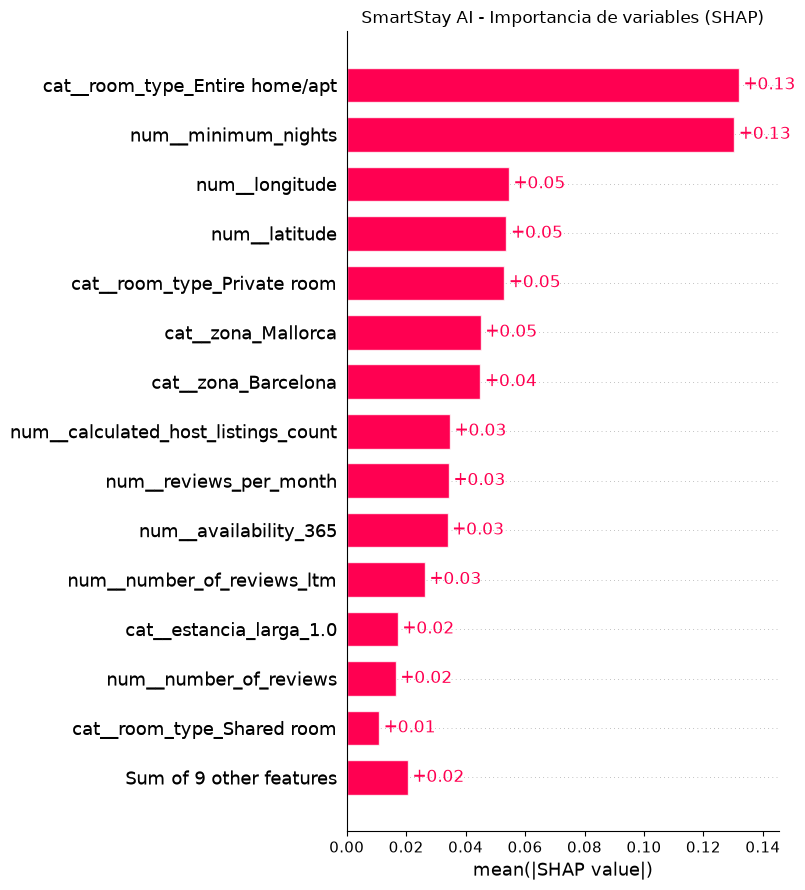

TOP 15 VARIABLES MÁS IMPORTANTES
--------------------------------
                           variable  importancia
     cat__room_type_Entire home/apt     0.131913
                num__minimum_nights     0.130357
                     num__longitude     0.054532
                      num__latitude     0.053732
        cat__room_type_Private room     0.052973
                 cat__zona_Mallorca     0.045066
                cat__zona_Barcelona     0.044964
num__calculated_host_listings_count     0.034714
             num__reviews_per_month     0.034353
              num__availability_365     0.033916
         num__number_of_reviews_ltm     0.026272
            cat__estancia_larga_1.0     0.017157
             num__number_of_reviews     0.016477
         cat__room_type_Shared room     0.010896
            cat__estancia_larga_0.0     0.009454


In [47]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Incorporar los nombres de las 23 variables
valores_shap.feature_names = list(nombres_variables)

# Gráfico de importancia global
shap.plots.bar(
    valores_shap,
    max_display=15,
    show=False
)

plt.title("SmartStay AI - Importancia de variables (SHAP)")
plt.tight_layout()
plt.show()

# Tabla de importancia media absoluta
importancia_shap = pd.DataFrame({
    "variable": nombres_variables,
    "importancia": np.abs(valores_shap.values).mean(axis=0)
}).sort_values("importancia", ascending=False)

print("TOP 15 VARIABLES MÁS IMPORTANTES")
print("--------------------------------")
print(importancia_shap.head(15).to_string(index=False))

### gráfico SHAP Beeswarm

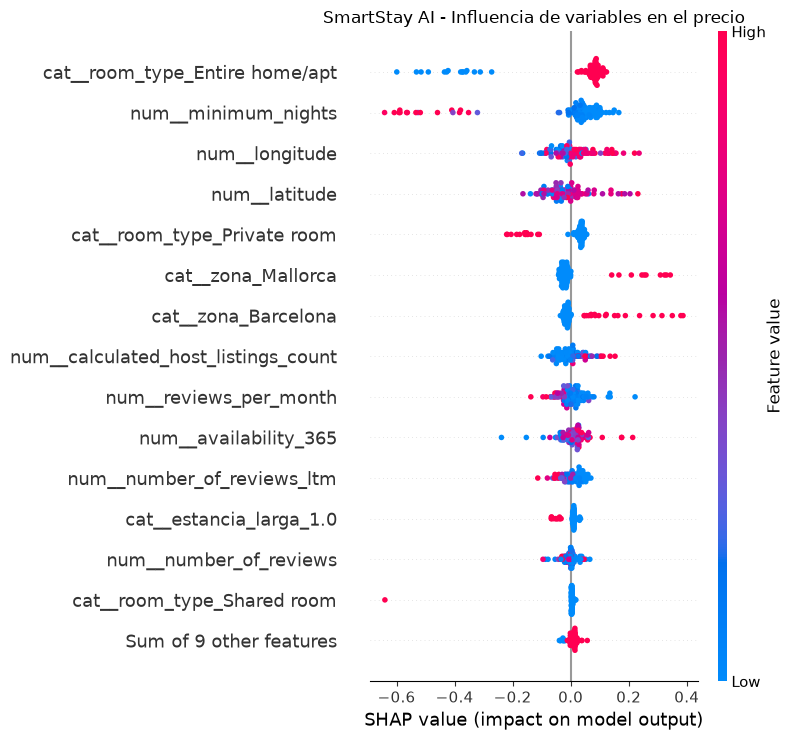

In [48]:
import shap
import matplotlib.pyplot as plt

shap.plots.beeswarm(
    valores_shap,
    max_display=15,
    show=False
)

plt.title("SmartStay AI - Influencia de variables en el precio")
plt.tight_layout()
plt.show()

### Interpretación de resultados SHAP

Para analizar la explicabilidad del modelo Random Forest especializado, se ha utilizado SHAP sobre una muestra de 100 alojamientos del conjunto de validación.

Los resultados muestran que las variables con mayor influencia en la predicción del precio son:

- **Tipo de alojamiento:** los alojamientos completos presentan contribuciones positivas al precio estimado, mientras que las habitaciones privadas tienden a reducirlo.
- **Noches mínimas:** las restricciones elevadas de estancia suelen asociarse con contribuciones negativas.
- **Ubicación geográfica:** las coordenadas y determinadas zonas, especialmente Mallorca y Barcelona, influyen considerablemente en las predicciones.
- **Actividad y disponibilidad:** las reseñas y la disponibilidad anual también contribuyen a las estimaciones, aunque con menor importancia.

El gráfico SHAP Beeswarm permite observar tanto la importancia como la dirección de las contribuciones de cada variable.

Dado que el modelo utiliza una transformación logarítmica de la variable objetivo (`log1p`), los valores SHAP representan contribuciones en la escala logarítmica del precio.

**Conclusión:** el modelo utiliza principalmente el tipo de alojamiento, las condiciones de estancia y la ubicación para estimar los precios. Estos resultados son coherentes con el problema de negocio, aunque no permiten establecer relaciones causales.

**Limitación:** el análisis se ha realizado sobre una muestra de 100 registros, por lo que sus resultados pueden variar al utilizar una muestra mayor.

## 7. Experimentos complementarios y análisis por tipo de alojamiento

### Winsorización 

In [49]:
import pandas as pd
import numpy as np

# Utilizamos únicamente el conjunto de entrenamiento original
precios = y_train.squeeze()

limites = [500, 750, 1000, 1500, 2000]

resultados = []

for limite in limites:
    precios_winsorizados = precios.clip(upper=limite)

    afectados = (precios > limite).sum()

    resultados.append({
        "Limite (€)": limite,
        "Registros afectados": afectados,
        "Porcentaje afectado": round(
            afectados / len(precios) * 100, 2
        ),
        "Media original": round(precios.mean(), 2),
        "Media winsorizada": round(
            precios_winsorizados.mean(), 2
        ),
        "Mediana winsorizada": round(
            precios_winsorizados.median(), 2
        )
    })

tabla_winsorizacion = pd.DataFrame(resultados)

print("ANÁLISIS DE WINSORIZACIÓN")
print("------------------------")
print(tabla_winsorizacion.to_string(index=False))

ANÁLISIS DE WINSORIZACIÓN
------------------------
 Limite (€)  Registros afectados  Porcentaje afectado  Media original  Media winsorizada  Mediana winsorizada
        500                 5887                 8.21          265.36             207.48                170.0
        750                 3093                 4.31          265.36             222.28                170.0
       1000                 1919                 2.68          265.36             230.97                170.0
       1500                  976                 1.36          265.36             240.44                170.0
       2000                  618                 0.86          265.36             245.87                170.0


### Experimento: Random Forest + log1p + winsorización

In [50]:
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd
import time

cv = KFold(n_splits=5, shuffle=True, random_state=42)

y_original = y_train.squeeze()

resultados = []
inicio = time.time()

for fold, (idx_train, idx_val) in enumerate(cv.split(X_train), 1):

    X_tr = X_train.iloc[idx_train]
    X_val = X_train.iloc[idx_val]

    y_tr = y_original.iloc[idx_train]
    y_val = y_original.iloc[idx_val]

    # Modelo sin winsorización
    modelo_original = clone(rf_log)
    modelo_original.fit(X_tr, y_tr)
    pred_original = modelo_original.predict(X_val)

    # Modelo con winsorización solo en entrenamiento
    modelo_winsor = clone(rf_log)
    y_tr_winsor = y_tr.clip(upper=1000)

    modelo_winsor.fit(X_tr, y_tr_winsor)
    pred_winsor = modelo_winsor.predict(X_val)

    resultados.append({
        "fold": fold,
        "MAE_original": mean_absolute_error(y_val, pred_original),
        "MAE_winsor": mean_absolute_error(y_val, pred_winsor)
    })

    print(f"Fold {fold}/5 completado")

tabla_comparacion = pd.DataFrame(resultados)

print("\nCOMPARACIÓN DE MODELOS")
print(tabla_comparacion.round(2).to_string(index=False))

print("\nMAE MEDIO ORIGINAL:",
      round(tabla_comparacion["MAE_original"].mean(), 2), "€")

print("MAE MEDIO WINSORIZADO:",
      round(tabla_comparacion["MAE_winsor"].mean(), 2), "€")

print("TIEMPO TOTAL:",
      round(time.time() - inicio, 2), "segundos")

Fold 1/5 completado
Fold 2/5 completado
Fold 3/5 completado
Fold 4/5 completado
Fold 5/5 completado

COMPARACIÓN DE MODELOS
 fold  MAE_original  MAE_winsor
    1        114.95      119.04
    2        104.62      108.47
    3        113.12      117.35
    4        100.00      102.03
    5        107.58      110.61

MAE MEDIO ORIGINAL: 108.05 €
MAE MEDIO WINSORIZADO: 111.5 €
TIEMPO TOTAL: 217.37 segundos


### Experimento adicional: winsorización de precios extremos

**Objetivo:** evaluar si la winsorización de la variable objetivo mejora la capacidad predictiva del Random Forest con transformación logarítmica.

Se ha establecido un límite superior de 1.000 € por noche, que afecta al 2,68 % de los registros del conjunto de entrenamiento.

Se han comparado dos modelos mediante validación cruzada de cinco particiones, utilizando las mismas observaciones de validación y calculando el MAE frente a los precios reales sin modificar.

| Modelo | MAE medio de validación |
|---|---:|
| Random Forest + log1p | **108,05 €** |
| Random Forest + log1p + winsorización | 111,50 € |

**Resultados:** la winsorización aumenta el MAE en 3,45 €, aproximadamente un 3,2 %. El modelo winsorizado obtiene peores resultados en las cinco particiones.

**Conclusión:** se descarta la winsorización a 1.000 € porque no mejora la precisión predictiva. La reducción de la influencia de los valores extremos durante el entrenamiento no compensa la pérdida de información sobre los precios elevados.

Este experimento muestra la importancia de validar las técnicas de tratamiento de valores extremos en lugar de asumir que siempre producen mejores modelos.

### analizar los tipos de alojamiento

In [51]:
import pandas as pd

# Solo datos de entrenamiento
analisis_tipos = X_train[["room_type"]].copy()
analisis_tipos["price"] = y_train.squeeze().to_numpy()

resumen_tipos = (
    analisis_tipos
    .groupby("room_type", dropna=False)
    .agg(
        alojamientos=("price", "count"),
        precio_medio=("price", "mean"),
        precio_mediano=("price", "median"),
        precio_maximo=("price", "max")
    )
    .round(2)
    .sort_values("alojamientos", ascending=False)
)

resumen_tipos["porcentaje"] = (
    resumen_tipos["alojamientos"]
    / len(analisis_tipos) * 100
).round(2)

print("DISTRIBUCIÓN POR TIPO DE ALOJAMIENTO")
print("------------------------------------")
print(resumen_tipos.to_string())

DISTRIBUCIÓN POR TIPO DE ALOJAMIENTO
------------------------------------
                 alojamientos  precio_medio  precio_mediano  precio_maximo  porcentaje
room_type                                                                             
Entire home/apt         59475        290.15           186.0        95042.0       82.96
Private room            11710        144.31            82.0       110700.0       16.33
Shared room               312         84.77            40.0         4200.0        0.44
Hotel room                194        261.39           210.5         1156.0        0.27


### entrenar el modelo A: viviendas completas, que son el grupo mayoritario.

In [52]:
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd
import time

cv_tipos = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

y_original = y_train.squeeze()

resultados_casas = []
inicio = time.time()

for fold, (idx_tr, idx_val) in enumerate(
    cv_tipos.split(X_train), 1
):

    X_tr = X_train.iloc[idx_tr]
    X_val = X_train.iloc[idx_val]

    y_tr = y_original.iloc[idx_tr]
    y_val = y_original.iloc[idx_val]

    # Modelo general
    general = clone(rf_log)
    general.fit(X_tr, y_tr)

    # Modelo especializado: viviendas completas
    mascara_tr = X_tr["room_type"] == "Entire home/apt"
    mascara_val = X_val["room_type"] == "Entire home/apt"

    especializado = clone(rf_log)
    especializado.fit(
        X_tr.loc[mascara_tr],
        y_tr.loc[mascara_tr]
    )

    # Mismas observaciones de validación
    X_val_casas = X_val.loc[mascara_val]
    y_val_casas = y_val.loc[mascara_val]

    pred_general = general.predict(X_val_casas)
    pred_especializado = especializado.predict(X_val_casas)

    resultados_casas.append({
        "fold": fold,
        "registros": len(X_val_casas),
        "MAE_general": mean_absolute_error(
            y_val_casas, pred_general
        ),
        "MAE_especializado": mean_absolute_error(
            y_val_casas, pred_especializado
        )
    })

    print(f"Fold {fold}/5 completado")

tabla_casas = pd.DataFrame(resultados_casas)

print("\nCOMPARACIÓN: VIVIENDAS COMPLETAS")
print("--------------------------------")
print(tabla_casas.round(2).to_string(index=False))

print("\nMAE GENERAL:",
      round(np.average(
          tabla_casas["MAE_general"],
          weights=tabla_casas["registros"]
      ), 2), "€")

print("MAE ESPECIALIZADO:",
      round(np.average(
          tabla_casas["MAE_especializado"],
          weights=tabla_casas["registros"]
      ), 2), "€")

print("TIEMPO:",
      round(time.time() - inicio, 2), "segundos")

Fold 1/5 completado
Fold 2/5 completado
Fold 3/5 completado
Fold 4/5 completado
Fold 5/5 completado

COMPARACIÓN: VIVIENDAS COMPLETAS
--------------------------------
 fold  registros  MAE_general  MAE_especializado
    1      11918       117.66             118.06
    2      11895       112.96             112.60
    3      11875       125.15             124.89
    4      11915       111.43             111.49
    5      11872       120.94             120.92

MAE GENERAL: 117.62 €
MAE ESPECIALIZADO: 117.59 €
TIEMPO: 209.26 segundos


### entrenar el modelo b : las habitaciones privadas

In [53]:
from sklearn.base import clone
from sklearn.model_selection import KFold
from sklearn.metrics import mean_absolute_error
import numpy as np
import pandas as pd
import time

cv_habitaciones = KFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

y_original = y_train.squeeze()
resultados_habitaciones = []

inicio = time.time()

for fold, (idx_tr, idx_val) in enumerate(
    cv_habitaciones.split(X_train), 1
):
    X_tr = X_train.iloc[idx_tr]
    X_val = X_train.iloc[idx_val]

    y_tr = y_original.iloc[idx_tr]
    y_val = y_original.iloc[idx_val]

    # Modelo general
    general = clone(rf_log)
    general.fit(X_tr, y_tr)

    # Seleccionar habitaciones privadas
    mascara_tr = X_tr["room_type"] == "Private room"
    mascara_val = X_val["room_type"] == "Private room"

    # Modelo especializado
    especializado = clone(rf_log)
    especializado.fit(
        X_tr.loc[mascara_tr],
        y_tr.loc[mascara_tr]
    )

    # Evaluación sobre las mismas habitaciones
    X_val_hab = X_val.loc[mascara_val]
    y_val_hab = y_val.loc[mascara_val]

    pred_general = general.predict(X_val_hab)
    pred_especializado = especializado.predict(X_val_hab)

    resultados_habitaciones.append({
        "fold": fold,
        "registros": len(X_val_hab),
        "MAE_general": mean_absolute_error(
            y_val_hab, pred_general
        ),
        "MAE_especializado": mean_absolute_error(
            y_val_hab, pred_especializado
        )
    })

    print(f"Fold {fold}/3 completado")

tabla_habitaciones = pd.DataFrame(resultados_habitaciones)

print("\nCOMPARACIÓN: HABITACIONES PRIVADAS")
print("----------------------------------")
print(tabla_habitaciones.round(2).to_string(index=False))

for columna in ["MAE_general", "MAE_especializado"]:
    mae = np.average(
        tabla_habitaciones[columna],
        weights=tabla_habitaciones["registros"]
    )
    print(f"{columna}: {mae:.2f} €")

print(
    "TIEMPO:",
    round(time.time() - inicio, 2),
    "segundos"
)

Fold 1/3 completado
Fold 2/3 completado
Fold 3/3 completado

COMPARACIÓN: HABITACIONES PRIVADAS
----------------------------------
 fold  registros  MAE_general  MAE_especializado
    1       3861        89.52              89.00
    2       3951        55.02              55.83
    3       3898        43.76              44.00
MAE_general: 62.65 €
MAE_especializado: 62.83 €
TIEMPO: 66.31 segundos


## 8. Selección del modelo definitivo y explicabilidad con SHAP

Tras comparar los modelos de regresión y los experimentos complementarios, se selecciona el **Random Forest general optimizado** como modelo principal de SmartStay AI.

Este modelo permite estimar el precio de alojamientos de diferentes zonas y rangos de precios sin limitar las predicciones a un segmento específico.

El modelo definitivo se guarda en `models/mejor_modelo.joblib` y se utiliza en la aplicación Streamlit.

### 8.1. Interpretabilidad del modelo mediante SHAP

Se utiliza SHAP para analizar la contribución de las variables a las predicciones del Random Forest general. Para evitar utilizar el conjunto de test, se ha entrenado una copia del modelo con el 80 % de los datos de desarrollo y se ha calculado SHAP sobre una muestra independiente del 20 % reservado para validación.

In [54]:
from sklearn.base import clone
from pathlib import Path
import joblib
import time

# 1. Crear una copia del Random Forest con log1p
modelo_final = clone(rf_log)

# 2. Entrenar con todos los datos de entrenamiento
inicio = time.time()

modelo_final.fit(X_train, y_train.squeeze())

tiempo = time.time() - inicio

# 3. Localizar la carpeta raíz del proyecto
ruta_actual = Path.cwd()

if ruta_actual.name == "notebooks":
    raiz_proyecto = ruta_actual.parent
else:
    raiz_proyecto = ruta_actual

# 4. Crear carpeta models si no existe
carpeta_modelos = raiz_proyecto / "models"
carpeta_modelos.mkdir(parents=True, exist_ok=True)

# 5. Guardar el pipeline completo
ruta_modelo = carpeta_modelos / "mejor_modelo.joblib"

joblib.dump(modelo_final, ruta_modelo)

# 6. Comprobar el archivo
print("MODELO DEFINITIVO GUARDADO")
print("--------------------------")
print("Ruta:", ruta_modelo.resolve())
print("Registros entrenamiento:", len(X_train))
print("Variables:", X_train.shape[1])
print("Tiempo entrenamiento:", round(tiempo, 2), "segundos")
print("Tamaño archivo:",
      round(ruta_modelo.stat().st_size / (1024**2), 2),
      "MB")

MODELO DEFINITIVO GUARDADO
--------------------------
Ruta: C:\Users\Jon.Gorricho\Desktop\SmartStay_AI\models\mejor_modelo.joblib
Registros entrenamiento: 71691
Variables: 11
Tiempo entrenamiento: 35.64 segundos
Tamaño archivo: 265.35 MB


In [55]:
import joblib
import numpy as np

# Cargar el modelo guardado
modelo_cargado = joblib.load(ruta_modelo)

# Seleccionar un ejemplo del entrenamiento
ejemplo = X_train.iloc[[0]]

# Predicción con el modelo original
pred_original = modelo_final.predict(ejemplo)[0]

# Predicción con el modelo cargado
pred_cargada = modelo_cargado.predict(ejemplo)[0]

print("VERIFICACIÓN DEL MODELO")
print("-----------------------")
print(f"Predicción original: {pred_original:.2f} €")
print(f"Predicción cargada:  {pred_cargada:.2f} €")

print(
    "Predicciones idénticas:",
    np.isclose(pred_original, pred_cargada)
)

print("Variables utilizadas:")
print(modelo_cargado.feature_names_in_)

VERIFICACIÓN DEL MODELO
-----------------------
Predicción original: 208.98 €
Predicción cargada:  208.98 €
Predicciones idénticas: True
Variables utilizadas:
['latitude' 'longitude' 'minimum_nights' 'number_of_reviews'
 'reviews_per_month' 'calculated_host_listings_count' 'availability_365'
 'number_of_reviews_ltm' 'zona' 'room_type' 'estancia_larga']


### comprobar MLflow

In [56]:
import mlflow
import pandas as pd

# Consultar los experimentos registrados
experimento = mlflow.get_experiment_by_name("SmartStay_AI")

if experimento is None:
    print("No se encuentra el experimento SmartStay_AI")
else:
    runs = mlflow.search_runs(
        experiment_ids=[experimento.experiment_id]
    )

    # Filtrar ejecuciones de redes neuronales
    mlp_runs = runs[
        runs["tags.mlflow.runName"]
        .fillna("")
        .str.contains("MLP", case=False)
    ]

    columnas = [
        c for c in mlp_runs.columns
        if c == "tags.mlflow.runName"
        or c.startswith("metrics.")
    ]

    print("EXPERIMENTOS MLP REGISTRADOS")
    print("----------------------------")

    print(
        mlp_runs[columnas].to_string(index=False)
        if not mlp_runs.empty
        else "No hay ejecuciones MLP registradas."
    )

EXPERIMENTOS MLP REGISTRADOS
----------------------------
 metrics.tiempo_seg  metrics.registros_entrenamiento  metrics.MAE_CV  metrics.MAE_CV_filtrado  metrics.R2_CV_filtrado  metrics.MAE_CV_original_mismo_segmento  metrics.RMSE_CV_filtrado  metrics.MAE_CV_filtrado_mismo_segmento  metrics.mejora_MAE  metrics.MAE_train  metrics.R2_CV  metrics.R2_train  metrics.RMSE_CV  metrics.RMSE_train  metrics.tiempo_optimizacion_seg  metrics.MAE_validacion  metrics.R2_validacion  metrics.tiempo_segundos  metrics.RMSE_validacion tags.mlflow.runName
         142.466770                              NaN      146.306838                      NaN                     NaN                                     NaN                       NaN                                     NaN                 NaN         145.431235       0.143155          0.126150       633.843695          670.087253                              NaN                     NaN                    NaN                      NaN                      

In [57]:
columnas_parametros = [
    c for c in mlp_runs.columns
    if c == "tags.mlflow.runName"
    or c.startswith("params.")
]

print("CONFIGURACIONES DE LAS REDES NEURONALES")
print("--------------------------------------")

print(
    mlp_runs[columnas_parametros]
    .set_index("tags.mlflow.runName")
    .T
    .to_string()
)

CONFIGURACIONES DE LAS REDES NEURONALES
--------------------------------------
tags.mlflow.runName                 MLP_Experimento_3 MLP_Experimento_2 MLP_Experimento_1  MLP_Base
params.modelo                                     NaN               NaN               NaN       NaN
params.cv_folds                                     3                 3                 3         3
params.transformacion_target                      NaN               NaN               NaN       NaN
params.precio_maximo_entrenamiento                NaN               NaN               NaN       NaN
params.n_estimators                               NaN               NaN               NaN       NaN
params.max_depth                                  NaN               NaN               NaN       NaN
params.min_samples_leaf                           NaN               NaN               NaN       NaN
params.max_features                               NaN               NaN               NaN       NaN
params.comparacion_mi

> **Selección final del proyecto:** el Random Forest general (`mejor_modelo.joblib`) es el modelo principal utilizado en Streamlit. El modelo especializado de la sección 9 queda como experimento complementario. Los resultados de test se presentan para evaluar el rendimiento final y no deben emplearse para reajustar o seleccionar retrospectivamente el modelo.

### Modelo general seleccionado — evaluación final

#### Random Forest Regressor optimizado (modelo definitivo)

Tras el entrenamiento y la evaluación de diferentes algoritmos de Machine Learning, el modelo general seleccionado para el uso en Streamlit es un **Random Forest Regressor optimizado**.

El objetivo del modelo es predecir el precio por noche de un alojamiento turístico en España a partir de sus características.

### 1. Configuración del modelo general

| Característica | Configuración |
|---|---|
| Algoritmo | Random Forest Regressor |
| Tipo de problema | Regresión supervisada |
| Variables de entrada | 11 |
| Registros de entrenamiento | 71.691 |
| Registros de test | 17.923 |
| `max_features` | 0.7 |
| `min_samples_leaf` | 2 |
| `random_state` | 42 |
| `n_jobs` | 1 |
| Transformación de la variable objetivo | `log1p` / `expm1` |
| Preprocesamiento | SimpleImputer, StandardScaler y OneHotEncoder |
| Archivo del modelo | `models/mejor_modelo.joblib` |

### 2. Variables utilizadas

**Variables numéricas:**

1. `latitude`
2. `longitude`
3. `minimum_nights`
4. `number_of_reviews`
5. `reviews_per_month`
6. `calculated_host_listings_count`
7. `availability_365`
8. `number_of_reviews_ltm`

**Variables categóricas:**

9. `zona`
10. `room_type`
11. `estancia_larga`

### 3. Resultados de evaluación

El modelo general se evaluó sobre 17.923 registros independientes de test.

| Métrica | Resultado |
|---|---:|
| MAE (Mean Absolute Error) | **100,87 €** |
| RMSE (Root Mean Squared Error) | **322,47 €** |
| R² (Coeficiente de determinación) | **0,3973** |

El modelo presenta un error absoluto medio de 100,87 € por noche y explica aproximadamente el 39,73 % de la variabilidad del precio en el conjunto de test.

### 4. Validación cruzada

Se realizó una validación cruzada de 3 particiones sobre los datos de entrenamiento.

| Métrica | Resultado |
|---|---:|
| MAE | 109,24 € |
| RMSE | 645,32 € |
| R² | 0,1885 |

### 5. Experimentos de selección de variables

Se compararon distintas configuraciones para estudiar el efecto de eliminar variables.

| Modelo | Variables | MAE CV |
|---|---:|---:|
| Modelo A — Original | 11 | 109,24 € |
| Modelo B — Sin latitud y longitud | 9 | 116,58 € |
| Modelo C — Sin estancia larga | 10 | 109,21 € |

**Conclusión:** se mantiene el modelo original de 11 variables. Eliminar las coordenadas empeora el resultado, mientras que eliminar `estancia_l

### 8.2. Gráfico de precios reales frente a predichos — evaluación final en test

Se representa el precio real frente a la predicción del **modelo general definitivo** sobre los 17.923 registros de test. La línea diagonal indica una predicción perfecta. El gráfico permite identificar la dispersión de los errores y los casos extremos. **El test se utiliza únicamente para evaluación final, no para seleccionar ni reajustar el modelo.**


Registros: 17,923
MAE: 100.87 € | RMSE: 322.47 € | R²: 0.3973


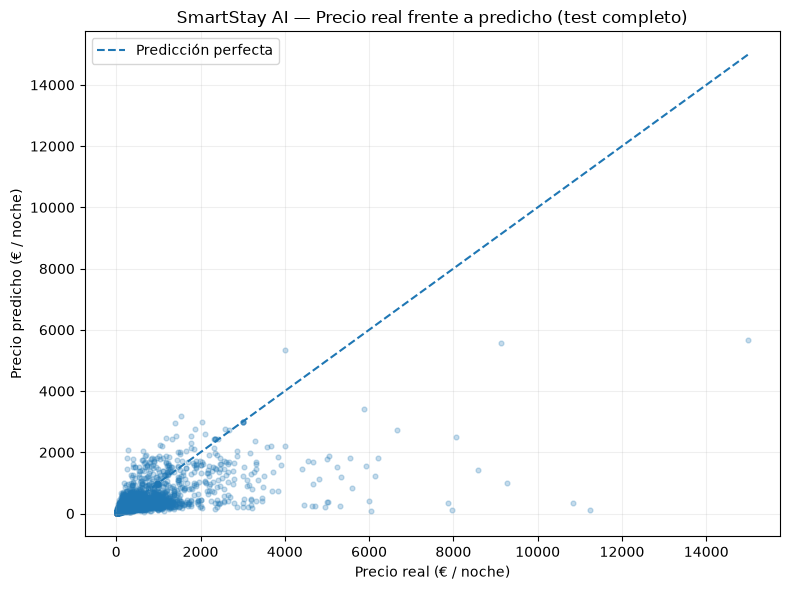

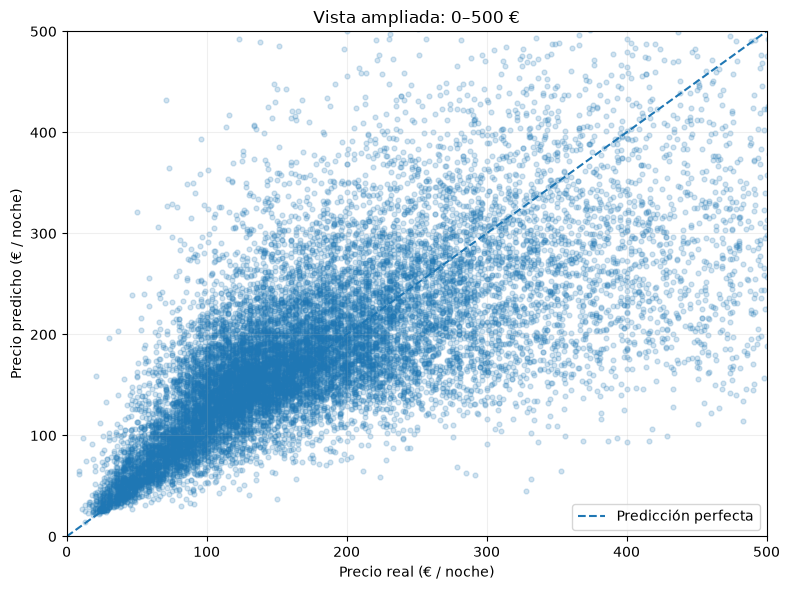

In [2]:
# Evaluación gráfica del modelo definitivo guardado (sin volver a entrenar)
from pathlib import Path
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

raiz = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
modelo_grafico = joblib.load(raiz / "models" / "mejor_modelo.joblib")
X_test_grafico = pd.read_csv(raiz / "data" / "processed" / "X_test.csv")
y_test_grafico = pd.read_csv(raiz / "data" / "processed" / "y_test.csv")["price"].to_numpy()

predicciones_test = np.asarray(modelo_grafico.predict(X_test_grafico)).ravel()
mae_test = mean_absolute_error(y_test_grafico, predicciones_test)
rmse_test = np.sqrt(mean_squared_error(y_test_grafico, predicciones_test))
r2_test = r2_score(y_test_grafico, predicciones_test)
print(f"Registros: {len(y_test_grafico):,}")
print(f"MAE: {mae_test:.2f} € | RMSE: {rmse_test:.2f} € | R²: {r2_test:.4f}")

fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test_grafico, predicciones_test, alpha=0.25, s=12)
limite = max(float(np.max(y_test_grafico)), float(np.max(predicciones_test)))
ax.plot([0, limite], [0, limite], linestyle="--", linewidth=1.5, label="Predicción perfecta")
ax.set(xlabel="Precio real (€ / noche)", ylabel="Precio predicho (€ / noche)",
       title="SmartStay AI — Precio real frente a predicho (test completo)")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# Vista ampliada para interpretar el rango habitual, sin excluir registros de las métricas
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(y_test_grafico, predicciones_test, alpha=0.2, s=12)
ax.plot([0, 500], [0, 500], "--", linewidth=1.5, label="Predicción perfecta")
ax.set(xlim=(0, 500), ylim=(0, 500), xlabel="Precio real (€ / noche)",
       ylabel="Precio predicho (€ / noche)", title="Vista ampliada: 0–500 €")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()


**Interpretación empresarial.** El MAE expresa cuánto se desvía en promedio la estimación del precio real en euros por noche; el RMSE penaliza especialmente los errores grandes y ayuda a detectar el impacto de anuncios atípicos. El R² indica la proporción de variabilidad del precio explicada por el modelo en test. Los puntos alejados de la diagonal representan recomendaciones potencialmente poco fiables. Por ello, SmartStay AI presenta la predicción como **apoyo a la decisión**, con reglas de negocio y supervisión humana, y no como una orden automática de modificar tarifas.

La segunda figura es una **ampliación visual** del rango 0–500 €; no modifica el cálculo de las métricas, que corresponde al conjunto completo de test.


### SHAP del modelo general mediante validación
El análisis SHAP del modelo seleccionado se realiza mediante una copia entrenada exclusivamente con la partición de entrenamiento. Las explicaciones se calculan sobre registros de validación no utilizados para ajustar esa copia. El modelo definitivo de Streamlit permanece sin cambios.

In [1]:

from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import shap

# Localizar la carpeta principal SmartStay_AI
RAIZ = Path.cwd()

if RAIZ.name == "notebooks":
    RAIZ = RAIZ.parent

print("Proyecto:", RAIZ)
print("SHAP:", shap.__version__)


Proyecto: c:\Users\Jon.Gorricho\Desktop\SmartStay_AI
SHAP: 0.54.1


c:\Users\Jon.Gorricho\AppData\Local\anaconda3\envs\ia_jag\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


### Cargar la configuración del modelo definitivo para el análisis SHAP de validación

In [2]:

modelo = joblib.load(
    RAIZ / "models" / "mejor_modelo.joblib"
)

# Extraer el pipeline entrenado
pipeline = modelo.regressor_

preprocesador = pipeline.named_steps["preprocessor"]
random_forest = pipeline.named_steps["regressor"]

print("Modelo:", type(random_forest).__name__)
print("Número de árboles:", random_forest.n_estimators)
print("max_features:", random_forest.max_features)
print("min_samples_leaf:", random_forest.min_samples_leaf)


Modelo: RandomForestRegressor
Número de árboles: 100
max_features: 0.7
min_samples_leaf: 2


In [17]:

from sklearn.model_selection import train_test_split
from sklearn.base import clone
import pandas as pd

# Cargar datos de entrenamiento
X_completo = pd.read_csv(
    RAIZ / "data" / "processed" / "X_train.csv"
)

y_completo = pd.read_csv(
    RAIZ / "data" / "processed" / "y_train.csv"
).squeeze("columns")

# Crear partición de validación
X_entreno, X_validacion, y_entreno, y_validacion = train_test_split(
    X_completo,
    y_completo,
    test_size=0.20,
    random_state=42
)

print("Entrenamiento:", X_entreno.shape)
print("Validación:", X_validacion.shape)


Entrenamiento: (57352, 11)
Validación: (14339, 11)


In [18]:

from sklearn.base import clone
import time

# Copiar la configuración del modelo definitivo
modelo_validacion = clone(modelo)

# Entrenar únicamente con el 80 %
inicio = time.time()

modelo_validacion.fit(X_entreno, y_entreno)

tiempo = time.time() - inicio

print("Modelo de validación entrenado correctamente")
print(f"Tiempo: {tiempo:.2f} segundos")
print("Registros entrenamiento:", len(X_entreno))
print("Registros validación:", len(X_validacion))


Modelo de validación entrenado correctamente
Tiempo: 22.23 segundos
Registros entrenamiento: 57352
Registros validación: 14339


### Preparar 50 registros para SHAP

In [19]:

# Extraer el pipeline de la copia entrenada
pipeline_val = modelo_validacion.regressor_

preprocesador_val = pipeline_val.named_steps["preprocessor"]
random_forest_val = pipeline_val.named_steps["regressor"]

# Seleccionar 50 registros de validación
X_shap_val = X_validacion.sample(
    n=50,
    random_state=42
)

# Aplicar el preprocesador entrenado
X_shap_transformado = preprocesador_val.transform(X_shap_val)

# Recuperar nombres de las variables transformadas
nombres_variables = preprocesador_val.get_feature_names_out()

print("Registros para SHAP:", X_shap_transformado.shape[0])
print("Variables transformadas:", X_shap_transformado.shape[1])
print("Nombres de variables:", len(nombres_variables))


Registros para SHAP: 50
Variables transformadas: 23
Nombres de variables: 23


### Calcular los valores SHAP

In [20]:

import shap
import numpy as np

# Crear explicador SHAP para el Random Forest de validación
explainer_val = shap.TreeExplainer(random_forest_val)

# Calcular valores SHAP
shap_values_val = explainer_val.shap_values(
    X_shap_transformado
)

print("Dimensiones SHAP:", np.shape(shap_values_val))
print("Dimensiones datos:", X_shap_transformado.shape)


Dimensiones SHAP: (50, 23)
Dimensiones datos: (50, 23)


### Generar el gráfico de importancia SHAP

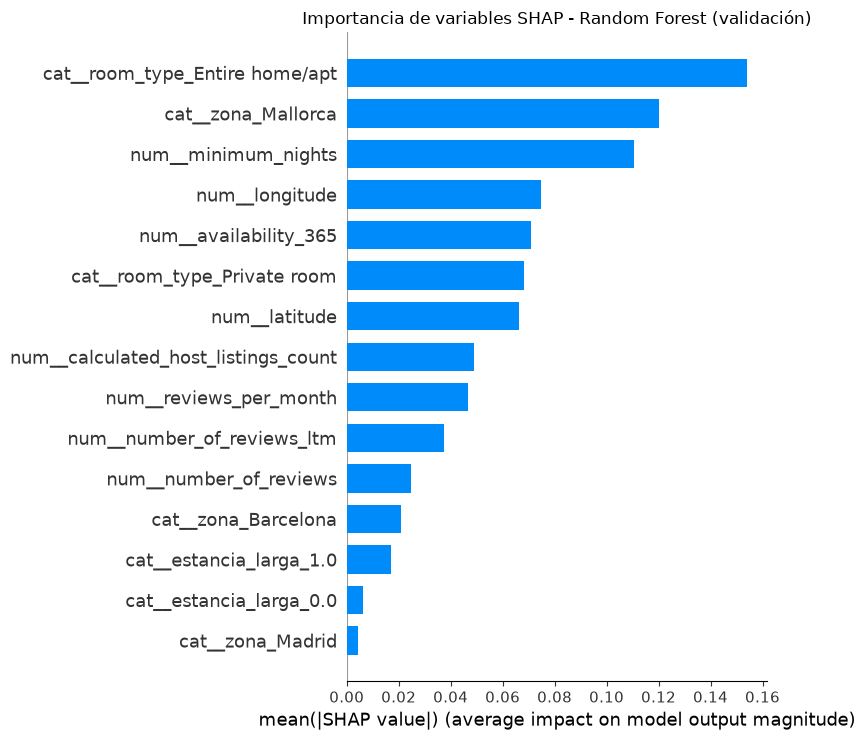

In [21]:

import matplotlib.pyplot as plt
import pandas as pd
import shap

# Convertir los datos transformados en DataFrame
X_shap_df_val = pd.DataFrame(
    X_shap_transformado,
    columns=nombres_variables
)

# Gráfico de importancia global SHAP
plt.figure(figsize=(11, 7))

shap.summary_plot(
    shap_values_val,
    X_shap_df_val,
    plot_type="bar",
    max_display=15,
    show=False
)

plt.title(
    "Importancia de variables SHAP - Random Forest (validación)"
)

plt.tight_layout()
plt.show()


Conclusión: el modelo utiliza principalmente el tipo de alojamiento, la zona geográfica y las condiciones de estancia para estimar el precio.

### Generar el gráfico SHAP beeswarm

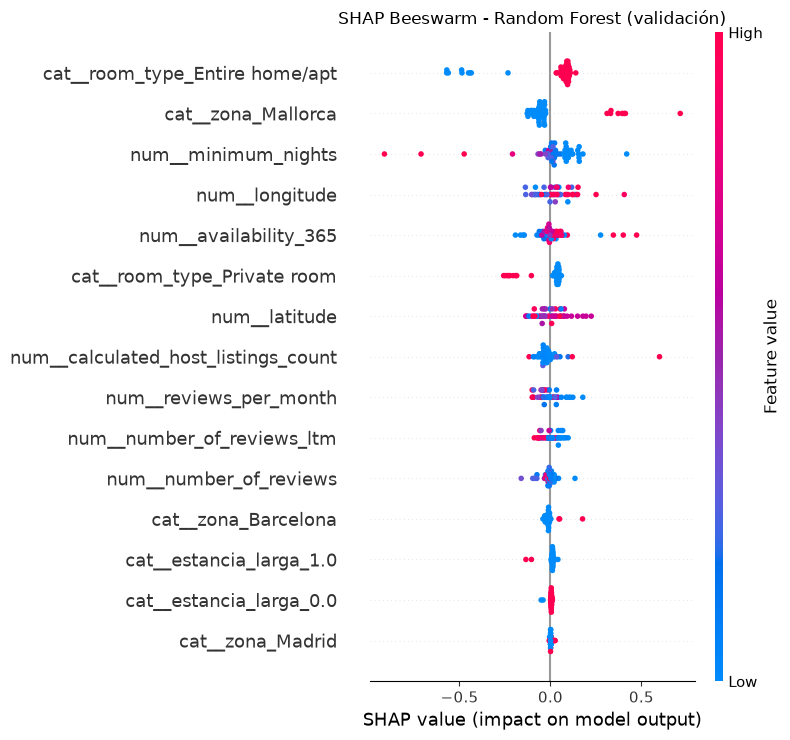

In [22]:

import matplotlib.pyplot as plt
import shap

plt.figure(figsize=(12, 8))

shap.summary_plot(
    shap_values_val,
    X_shap_df_val,
    max_display=15,
    show=False
)

plt.title(
    "SHAP Beeswarm - Random Forest (validación)"
)

plt.tight_layout()
plt.show()


### Interpretación SHAP del Random Forest mediante validación

Para interpretar el comportamiento del Random Forest se ha realizado un análisis SHAP utilizando una partición independiente de validación.

Se ha dividido el conjunto de desarrollo en un 80 % para entrenamiento (57.352 registros) y un 20 % para validación (14.339 registros).

Se ha entrenado una copia del modelo seleccionado, conservando su configuración e hiperparámetros, sin modificar el modelo definitivo utilizado en Streamlit.

El análisis SHAP se ha calculado sobre una muestra de 50 alojamientos de validación, con 23 variables después del preprocesamiento.

**Resultados principales:**

1. **Tipo de alojamiento:** disponer de una vivienda completa contribuye generalmente a incrementar la predicción, mientras que una habitación privada tiende a reducirla.
2. **Zona geográfica:** Mallorca presenta contribuciones positivas relevantes en varios alojamientos.
3. **Noches mínimas:** los valores elevados suelen contribuir a reducir la predicción del modelo.
4. **Localización:** la latitud y la longitud influyen en la estimación, con efectos diferentes según el alojamiento.
5. **Disponibilidad anual:** muestra un comportamiento variable, sin una dirección única.

**Conclusión:**

El modelo utiliza principalmente el tipo de alojamiento, la ubicación y las condiciones de estancia para estimar el precio.

Los valores SHAP se interpretan en la escala `log1p(precio)`, debido a la transformación de la variable objetivo utilizada durante el entrenamiento.

Este análisis corresponde a una copia entrenada para validación, con la misma configuración que el modelo definitivo, y no a una explicación directa de los árboles del modelo desplegado.

De esta forma se analiza la importancia de las variables sin utilizar los registros de test para calcular SHAP.